# 27 — Regional equity pricing errors and joint zero-alpha tests

Add constant **World, US and national equity** pricing-error intercepts for **Poland, Czechia,
Romania, Sweden and Hungary**, in **USD/EUR**, under **scalar and diagonal BEKK**. Keep the frozen
**October 2014–September 2026 (144 months)** common sample and **Python 3 (base)** kernel.

Use constant national local pricing as the main comparison and notebook 26's time-varying local
pricing as a separate sensitivity, following the earlier Hungarian alpha check. Both keep the same
time-varying world/FX designs, corrected priced FX means and constant US local price. Jointly
re-estimate all free parameters when alphas are freed. Verify 40 zero-alpha references and estimate
40 free-alpha models; no fetching, installation, kernel changes or earlier-output edits.

In [1]:
# Fixed common sample; adjustable numerical and diagnostic controls.
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.70)]
MAX_ITER = 3000
MAX_ITER_OVERRIDES = {("HU", "EUR", "diagonal", "constant_local"): 8000}
TEST_LAGS = 12
HAC_LAGS = (0, 3, 6, 12)
REUSE_FITS = True
MODEL_VERSION = "regional_equity_pricing_errors_v1"
WORLD_INSTRUMENTS = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
LOCAL_FORMS = ["constant_local", "time_varying_local"]  # main comparison, then sensitivity
PREVIOUS_MANIFEST_SHA = "f43a637a5f8cba58aa5dadaa0cf6d80c512eebd3b65f80b86eadeac1b701d6ce"
LOCK_HASHES = {
    "regional_dataset_inputs.json": "0ceeef569dc4513d8534faf346509b22245db7ebff63abeb77044fc1474be208",
    "research_synthesis_inputs.json": "4fc2f36215746dd0ad0fef3ac41d8953f4abc6f1a3a36b526813437a26f081ee",
}

from pathlib import Path
from io import BytesIO
import hashlib, importlib, importlib.metadata, json, os, platform, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2
from packaging.version import Version
versions = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "ipykernel"]}
if Version(versions["statsmodels"]) < Version("0.15.0"):
    raise RuntimeError("Use the base environment already used for notebooks 20–22 (statsmodels 0.15.0 or later).")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != versions["statsmodels"]:
    raise RuntimeError("Restart the existing base kernel to discard stale statsmodels imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
import pricing_robustness as core
importlib.reload(core)
import regional_pricing_errors as engine
importlib.reload(engine)

NAMES = {"PL": "Poland", "CZ": "Czechia", "RO": "Romania", "SE": "Sweden", "HU": "Hungary"}
LOCAL_CURRENCIES = {"PL": "PLN", "CZ": "CZK", "RO": "RON", "SE": "SEK", "HU": "HUF"}
COUNTRY_ORDER, CURRENCIES, COVARIANCES = ["HU", "PL", "CZ", "RO", "SE"], ["USD", "EUR"], ["scalar", "diagonal"]
ASSETS = ["World", "US", "National", "National FX", "Other FX"]
COLORS = {"PL": "#285f9e", "CZ": "#2a8a70", "RO": "#9469ad", "SE": "#b77d13", "HU": "#c4483b"}
PREVIOUS = ROOT/"output"/"26_regional_time_varying_local"/"2014-10_2026-09"/"local_19bcb384"
FX_PREVIOUS = ROOT/"output"/"25_regional_time_varying_currency"/"2014-10_2026-09"/"fx_a9208202"
assert LOCAL_FORMS == ["constant_local", "time_varying_local"]
spec = {"local_forms": LOCAL_FORMS, "alpha_equations": ASSETS[:3], "alpha_scale": "fixed sample equity SD",
        "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA}
instrument_id = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:8]
OUT = ROOT/"output"/"27_regional_pricing_errors"/"2014-10_2026-09"/f"alpha_{instrument_id}"
OUT.mkdir(parents=True, exist_ok=True)
def sha(raw): return hashlib.sha256(raw).hexdigest()
engine_hashes = {name: sha((ROOT/name).read_bytes()) for name in
    ["regional_pricing_errors.py", "regional_local_pricing.py", "regional_fx_price_variation.py", "regional_world_pricing.py", "regional_currency_pricing.py", "pricing_robustness.py", "regional_pricing_baseline.py", "regional_covariance_sensitivity.py"]}
assert 2 <= TEST_LAGS <= 24 and tuple(HAC_LAGS) == (0, 3, 6, 12)
assert all(a > 0 and b > 0 and a+b < 1 for a, b in START_DYNAMICS)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
pd.set_option("display.max_columns", 14)
print("Python:", sys.executable)
print("Packages:", versions)
print("Alpha engine SHA-256:", engine_hashes["regional_pricing_errors.py"])

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8', 'ipykernel': '7.2.0'}
Alpha engine SHA-256: 4c5966c73213ec518fae6da37c1b547b9f6c64bc7d42c63305d59c4c8b32dda6


## 1. Verify the frozen sample and reference fits

Verify notebook 26's pinned manifest, all protected files, outputs and engines. Keep the ten
five-series datasets, USD/EUR conversion identities and the same matched Hungarian sample.
Constant-local references are the unchanged notebook-25 fits archived in notebook 26; the
varying-local sensitivity uses notebook 26's new fits. No full-history Hungarian model is substituted.
USD/EUR views and country systems share data and must not be treated as independent replications.

In [2]:
def verify_inputs():
    raw = (PREVIOUS/"estimation_manifest.json").read_bytes()
    if sha(raw) != PREVIOUS_MANIFEST_SHA: raise ValueError("Notebook-26 manifest changed.")
    previous = json.loads(raw)
    assert previous["input_locks"] == LOCK_HASHES
    assert (previous["first"], previous["last"], previous["observations_per_fit"]) == ("2014-10", "2026-09", 144)
    expected = previous["input_file_hashes"].copy()
    for name, checksum in previous["outputs"].items():
        expected[(PREVIOUS/name).relative_to(ROOT).as_posix()] = checksum
    expected[(PREVIOUS/"estimation_manifest.json").relative_to(ROOT).as_posix()] = PREVIOUS_MANIFEST_SHA
    expected.update(previous["engines"])
    locks = {}
    for name, checksum in LOCK_HASHES.items():
        content = (ROOT/name).read_bytes()
        if sha(content) != checksum: raise ValueError(f"Changed input lock: {name}")
        locks[name] = json.loads(content)
    for path, checksum in expected.items():
        if sha((ROOT/path).read_bytes()) != checksum: raise ValueError(f"Changed frozen input: {path}")
    regional = locks["regional_dataset_inputs.json"]
    assert sha((ROOT/regional["root"]/"manifest.json").read_bytes()) == regional["manifest_sha256"]
    return locks, expected

locks, input_hashes = verify_inputs()
regional = locks["regional_dataset_inputs.json"]
assert (regional["common_start"], regional["common_end"], regional["common_months"]) == ("2014-10", "2026-09", 144)
months = pd.period_range("2014-10", "2026-09", freq="M", name="month")
frames, samples, scales, source_hashes, audit_rows = {}, {}, {}, {}, []
for country in COUNTRY_ORDER:
    for currency in CURRENCIES:
        path = ROOT/regional["root"]/"common"/f"{country}_{currency}.csv"
        raw = path.read_bytes()
        assert sha(raw) == input_hashes[path.relative_to(ROOT).as_posix()]
        d = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
        d.index = pd.PeriodIndex(d.index, freq="M", name="month")
        assert d.index.equals(months) and np.isfinite(d.to_numpy()).all() and d.flag_known_index_backcast.sum() == 0
        for asset in ["world", "us", "local"]:
            np.testing.assert_allclose(d[f"rx_{asset}"], d[f"r_{asset}"]-d.rf, atol=1e-12, rtol=0)
        y = d[["rx_world", "rx_us", "rx_local", "fx_local", "fx_other"]].to_numpy()*100
        scale = y.std(axis=0, ddof=1)
        correlation = np.cov(y, rowvar=False)/np.outer(scale, scale)
        assert (scale > 0).all() and np.linalg.eigvalsh(correlation).min() > 0 and np.linalg.matrix_rank(y-y.mean(axis=0)) == 5
        key = (country, currency)
        frames[key], samples[key], scales[key], source_hashes[key] = d, y, scale, sha(raw)
        np.testing.assert_array_equal(y[:, [0, 1, 4]], samples[("HU", currency)][:, [0, 1, 4]])
        audit_rows.append({"country": country, "name": NAMES[country], "perspective": currency,
            "first": str(months[0]), "last": str(months[-1]), "months": len(y), "rank": 5,
            "min_correlation_eigenvalue": np.linalg.eigvalsh(correlation).min(), "correlation_condition": np.linalg.cond(correlation),
            "national_FX_sd_pp": scale[3], "national_FX_currency": LOCAL_CURRENCIES[country],
            "other_FX_currency": "EUR" if currency == "USD" else "USD"})
transform = np.eye(5)
transform[:3, 4], transform[3, 4], transform[4, 4] = -1., -1., -1.
for country in COUNTRY_ORDER:
    converted = samples[(country, "USD")]@transform.T
    converted[:, :3] += ((frames[(country, "USD")].rf-frames[(country, "EUR")].rf)*100).to_numpy()[:, None]
    np.testing.assert_allclose(converted, samples[(country, "EUR")], atol=1e-10, rtol=0)
input_audit = pd.DataFrame(audit_rows)
display(input_audit.set_index(["name", "perspective"])[["months", "rank", "correlation_condition", "national_FX_sd_pp", "other_FX_currency"]].round(4))
print("Verified", len(input_hashes), "protected files and all ten five-series input systems.")

months  rank  correlation_condition  national_FX_sd_pp  \
name    perspective                                                           
Hungary USD             144     5               177.8975             3.0207   
        EUR             144     5               123.6042             1.7874   
Poland  USD             144     5               196.7334             2.9611   
        EUR             144     5               135.7310             1.4953   
Czechia USD             144     5               218.7463             2.6464   
        EUR             144     5               152.3439             1.1305   
Romania USD             144     5               168.0376             2.1759   
        EUR             144     5               110.8968             0.5283   
Sweden  USD             144     5               242.4797             2.9674   
        EUR             144     5               174.9449             1.7097   

                    other_FX_currency  
name    perspective                    
Hungary USD                       EUR  
        EUR                       USD  
Poland  USD                       EUR  
        EUR                       USD  
Czechia USD                       EUR  
        EUR                       USD  
Romania USD                       EUR  
        EUR                       USD  
Sweden  USD                       EUR  
        EUR                       USD

Verified 1332 protected files and all ten five-series input systems.


## 2. Keep all conditioning designs fixed

Load notebook 26's verified world, two FX and national-local designs without new transformations,
lags, predictors or observation removal. Constant local pricing restricts only the national-local
design to an intercept; the sensitivity retains its audited inflation-gap change and, for Czechia,
varying regime indicator. Normalizers, inherited US-inflation carry flags and source audits remain
pinned. The three new alpha coefficients introduce no new instruments.

Constant local pricing is the common main comparison because notebook 26's BIC favored it in
18/20 systems; retain the same time-varying-local sensitivity for every country, including Romania/EUR.
This is an exploratory sequence after model comparison, not a pre-registered or selection-adjusted test.
The augmented fixed-covariance mean-loading rank check below screens alpha/risk-price collinearity;
full joint curvature and SE stability still determine whether inference is reported.

In [3]:
upstream = json.loads((PREVIOUS/"estimation_manifest.json").read_text())
source_conditioning = pd.read_csv(PREVIOUS/"conditioning_design.csv", float_precision="round_trip")
source_normalizers = pd.read_csv(PREVIOUS/"instrument_transform.csv", float_precision="round_trip")
source_design_audit = pd.read_csv(PREVIOUS/"design_audit.csv", float_precision="round_trip")
source_quality_flags = pd.read_csv(PREVIOUS/"inflation_quality_flags.csv")
quality_flags = pd.concat([source_quality_flags.assign(local_form=form,
    local_uses_carried_US=source_quality_flags.local_uses_carried_US if form == "time_varying_local" else False)
    for form in LOCAL_FORMS], ignore_index=True)
source_designs, source_names = {}, {}
for key in samples:
    country, currency = key; source_designs[key], source_names[key] = {}, {}
    for factor in ["W", "H", "O", "L"]:
        g = source_conditioning.query("country == @country and perspective == @currency and factor == @factor")
        names = list(g.instrument.unique())
        D = np.column_stack([g.loc[g.instrument.eq(name), "value"].to_numpy() for name in names])
        # Preserve notebook 26's array order for identical floating-point reference scores.
        D = np.array(D, order="F" if factor != "L" or len(names) > 2 else "C")
        for name in names: assert list(g.loc[g.instrument.eq(name), "month"]) == months.astype(str).tolist()
        row = source_design_audit.query("country == @country and perspective == @currency and factor == @factor").iloc[0]
        assert sha(D.tobytes()) == row.design_sha256 and np.isfinite(D).all() and np.linalg.matrix_rank(D) == D.shape[1]
        source_designs[key][factor], source_names[key][factor] = D, names

def case_designs(key, local_form):
    return {a: d if a != "L" or local_form == "time_varying_local" else np.ones((len(months), 1))
            for a, d in source_designs[key].items()}
def case_names(key, local_form):
    return {a: names if a != "L" or local_form == "time_varying_local" else ["constant"]
            for a, names in source_names[key].items()}
def case_normalizers(key, local_form):
    country, currency = key
    g = source_normalizers.query("country == @country and perspective == @currency")
    return g.loc[g.factor.ne("L")] if local_form == "constant_local" else g
conditioning_rows, design_rows, transform_rows = [], [], []
for key in samples:
    country, currency = key
    for local_form in LOCAL_FORMS:
        D, names = case_designs(key, local_form), case_names(key, local_form)
        for factor, values in D.items():
            design_rows.append({"country": country, "perspective": currency, "local_form": local_form, "factor": factor,
                "rank": np.linalg.matrix_rank(values), "columns": values.shape[1], "design_sha256": sha(values.tobytes())})
            conditioning_rows.extend({"country": country, "perspective": currency, "local_form": local_form, "factor": factor,
                "instrument": name, "month": str(month), "value": values[t, j]}
                for j, name in enumerate(names[factor]) for t, month in enumerate(months))
        transform_rows.extend({"local_form": local_form, **r} for r in case_normalizers(key, local_form).to_dict("records"))
conditioning, design_audit, transform_table = map(pd.DataFrame, [conditioning_rows, design_rows, transform_rows])
reference_summary = pd.read_csv(PREVIOUS/"fit_summary.csv", float_precision="round_trip")
figure_files = []
def save_plot(name):
    plt.savefig(OUT/name, dpi=170, bbox_inches="tight", metadata={"Software": "Regional equity-alpha notebook 27"})
    figure_files.append(name); plt.show(); plt.close()
display(design_audit.query("factor == 'L'").set_index(["country", "perspective", "local_form"])[["rank", "columns"]])
print("All 40 source conditioning matrices verified; world/FX designs and frozen timing are unchanged.")

rank  columns
country perspective local_form                       
HU      USD         constant_local         1        1
                    time_varying_local     2        2
        EUR         constant_local         1        1
                    time_varying_local     2        2
PL      USD         constant_local         1        1
                    time_varying_local     2        2
        EUR         constant_local         1        1
                    time_varying_local     2        2
CZ      USD         constant_local         1        1
                    time_varying_local     3        3
        EUR         constant_local         1        1
                    time_varying_local     3        3
RO      USD         constant_local         1        1
                    time_varying_local     2        2
        EUR         constant_local         1        1
                    time_varying_local     2        2
SE      USD         constant_local         1        1
                    time_varying_local     2        2
        EUR         constant_local         1        1
                    time_varying_local     2        2

All 40 source conditioning matrices verified; world/FX designs and frozen timing are unchanged.


## 3. Add the three equity intercepts and check exact nesting

For equity i in {World, US, national}:

$$
\boxed{\mu_{i,t}=\alpha_i+\lambda_{W,t}H_{iW,t}+\lambda_{FX,c,t}H_{i,FXc,t}
+\lambda_{FX,o,t}H_{i,FXo,t}+\mathbf{1}_{i\in\{US,national\}}\lambda_{i,t}H_{ii,t}.}
$$

World has no own-local term. **Neither FX mean receives an added intercept**; both retain the
corrected pricing restriction. National local prices are constant in the main comparison and
varying in the sensitivity. The US local price stays constant. All other free parameters are
jointly re-estimated: adding alpha changes innovations and subsequent conditional covariances.

$$
\boxed{H_0:\alpha_W=\alpha_{US}=\alpha_{national}=0\quad(3\ \mathrm{df}).}
$$

These are constant pricing discrepancies in **monthly log percentage points**, not realized trading
profits, local risk prices, or the BEKK shock weights also called alpha. Optimize each intercept in
units of its equity's fixed sample SD, with no artificial alpha bounds; retain existing nuisance bounds.
Each free-alpha model adds exactly **three parameters**. Check every reference, zero-alpha nesting,
nonzero-alpha analytic gradients, covariance feedback and augmented mean-loading rank before fitting.

In [4]:
zero_fits, check_rows, loading_rows = {}, [], []
for key, y in samples.items():
    country, currency = key; scale = scales[key]
    for local_form in LOCAL_FORMS:
        D = case_designs(key, local_form)
        for covariance in COVARIANCES:
            record_root, suffix = (FX_PREVIOUS, "time_varying_fx") if local_form == "constant_local" else (PREVIOUS, "time_varying_local")
            record = json.loads((record_root/f"fit_{country}_{currency}_{covariance}_{suffix}.json").read_text())
            config = record["config"]
            assert (config["country"], config["perspective"], config["covariance"], config["source_sha256"]) == (country, currency, covariance, source_hashes[key])
            used = ["W", "H", "O"] if local_form == "constant_local" else ["W", "H", "O", "L"]
            assert record["fingerprint"] == sha(json.dumps(config, sort_keys=True).encode()+y.tobytes()+b"".join(D[a].tobytes() for a in used))
            theta0 = np.asarray(record["theta"])
            base = engine.filter_model(theta0, y, D, scale, False, covariance)
            with np.load(PREVIOUS/f"parameters_{country}_{currency}_{covariance}_{local_form}.npz", allow_pickle=False) as saved:
                np.testing.assert_array_equal(theta0, saved["theta"])
                for field in ["H", "mu", "errors", "scores"]: np.testing.assert_allclose(base[field], saved[field], atol=1e-12, rtol=0)
            row = reference_summary.query("country == @country and perspective == @currency and covariance == @covariance and model == @local_form").iloc[0]
            assert abs(base["losses"].mean()-record["mean_nll"]) < 1e-8 and abs(-base["losses"].sum()-row.loglik) < 1e-8
            assert np.abs(engine.projected_gradient(theta0, base["scores"].mean(axis=0), engine.bounds(D, False, covariance))).max() < 1e-4
            zero_fits[(*key, covariance, local_form)] = {"theta": theta0, "filter": base, "free_alpha": False,
                "y": y, "scales": scale, "designs": D, "record": record}
            nested = engine.filter_model(engine.expand_zero(theta0), y, D, scale, True, covariance)
            for field in ["H", "mu", "errors", "losses"]: np.testing.assert_allclose(nested[field], base[field], atol=1e-12, rtol=0)
            np.testing.assert_allclose(nested["scores"][:, :-3], base["scores"], atol=1e-12, rtol=0)
            ids = engine.price_indices(D, True); k = 5+sum(d.shape[1]-1 for d in D.values())
            M = np.zeros((len(y), 5, k+3))
            for label, factor in [("W", 0), ("H", 3), ("O", 4)]: M[:, :, ids[label]] = base["H"][:, :, factor, None]*D[label][:, None, :]
            M[:, 1, 1] = base["H"][:, 1, 1]
            M[:, 2, ids["L"]] = base["H"][:, 2, 2, None]*D["L"]
            M[:, np.arange(3), k+np.arange(3)] = 1.
            flat = M.reshape(-1, k+3); norms = np.linalg.norm(flat, axis=0)
            assert (norms > 0).all()
            scaled = flat/norms; rank, condition = np.linalg.matrix_rank(scaled), np.linalg.cond(scaled)
            assert rank == k+3 and np.isfinite(condition)
            loading_rows.append({"country": country, "perspective": currency, "covariance": covariance, "local_form": local_form,
                "rank": rank, "columns": k+3, "column_scaled_condition": condition})
            theta = engine.initial_theta(y, D, scale, True, covariance)
            for label in ids: theta[ids[label][1:]] = np.linspace(.1, -.08, len(ids[label])-1)
            theta[-3:] = [.1, -.08, .06]
            if covariance == "diagonal": theta[-13:-3] += np.linspace(-.1, .1, 10)
            sub = {a: d[:35] for a, d in D.items()}
            analytic = engine.objective(theta, y[:35], sub, scale, True, covariance)[1]
            numeric = engine.numerical_gradient(lambda t: engine.objective(t, y[:35], sub, scale, True, covariance)[0], theta)
            np.testing.assert_allclose(analytic, numeric, atol=5e-6, rtol=5e-5)
            probe = engine.filter_model(theta, y, D, scale, True, covariance)
            expected = probe["world_prices"][:, None]*probe["H"][:, :, 0]
            expected += probe["fx_prices"][:, 0, None]*probe["H"][:, :, 3]+probe["fx_prices"][:, 1, None]*probe["H"][:, :, 4]
            expected[:, 1] += probe["prices"][1]*probe["H"][:, 1, 1]
            expected[:, 2] += probe["local_prices"]*probe["H"][:, 2, 2]
            np.testing.assert_allclose(probe["pricing_mu"], expected, atol=1e-12, rtol=0)
            expected[:, :3] += probe["equity_alphas"]
            np.testing.assert_allclose(probe["mu"], expected, atol=1e-12, rtol=0)
            altered = theta.copy(); altered[-3:] = 0
            assert np.abs(probe["H"][1:]-engine.filter_model(altered, y, D, scale, True, covariance)["H"][1:]).max() > 1e-6
            if local_form == "constant_local":
                varying_design = case_designs(key, "time_varying_local")
                lifted = np.r_[engine.previous.lift_constant_local(theta[:-3], varying_design), theta[-3:]]
                cross_form = engine.filter_model(lifted, y, varying_design, scale, True, covariance)
                for field in ["H", "mu", "losses"]: np.testing.assert_allclose(probe[field], cross_form[field], atol=1e-12, rtol=0)
            if covariance == "scalar":
                other = engine.filter_model(engine.expand_scalar(theta, True), y, D, scale, True, "diagonal")
                for field in ["H", "mu", "losses"]: np.testing.assert_allclose(probe[field], other[field], atol=1e-12, rtol=0)
            check_rows.append({"country": country, "perspective": currency, "covariance": covariance, "local_form": local_form,
                "zero_alpha_parameters": len(theta0), "free_alpha_parameters": len(theta), "added_parameters": len(theta)-len(theta0),
                "max_gradient_error": np.abs(analytic-numeric).max(), "zero_nesting_max_H_error": np.abs(nested["H"]-base["H"]).max()})
checks, mean_loading_audit = pd.DataFrame(check_rows), pd.DataFrame(loading_rows)
display(checks.groupby(["local_form", "covariance"])[["zero_alpha_parameters", "free_alpha_parameters", "added_parameters", "max_gradient_error"]].max())
display(mean_loading_audit.set_index(["country", "perspective", "covariance", "local_form"]).round(4))
print("All 40 references, zero-alpha nesting, alpha/price gradients, covariance feedback and mean-loading checks passed.")

zero_alpha_parameters  free_alpha_parameters  \
local_form         covariance                                                 
constant_local     diagonal                       42                     45   
                   scalar                         34                     37   
time_varying_local diagonal                       44                     47   
                   scalar                         36                     39   

                               added_parameters  max_gradient_error  
local_form         covariance                                        
constant_local     diagonal                   3        3.328400e-08  
                   scalar                     3        3.426996e-08  
time_varying_local diagonal                   3        3.276685e-08  
                   scalar                     3        3.394413e-08

rank  columns  \
country perspective covariance local_form                          
HU      USD         scalar     constant_local        19       19   
                    diagonal   constant_local        19       19   
                    scalar     time_varying_local    20       20   
                    diagonal   time_varying_local    20       20   
        EUR         scalar     constant_local        19       19   
                    diagonal   constant_local        19       19   
                    scalar     time_varying_local    20       20   
                    diagonal   time_varying_local    20       20   
PL      USD         scalar     constant_local        19       19   
                    diagonal   constant_local        19       19   
                    scalar     time_varying_local    20       20   
                    diagonal   time_varying_local    20       20   
        EUR         scalar     constant_local        19       19   
                    diagonal   constant_local        19       19   
                    scalar     time_varying_local    20       20   
                    diagonal   time_varying_local    20       20   
CZ      USD         scalar     constant_local        20       20   
                    diagonal   constant_local        20       20   
                    scalar     time_varying_local    22       22   
                    diagonal   time_varying_local    22       22   
        EUR         scalar     constant_local        20       20   
                    diagonal   constant_local        20       20   
                    scalar     time_varying_local    22       22   
                    diagonal   time_varying_local    22       22   
RO      USD         scalar     constant_local        19       19   
                    diagonal   constant_local        19       19   
                    scalar     time_varying_local    20       20   
                    diagonal   time_varying_local    20       20   
        EUR         scalar     constant_local        19       19   
                    diagonal   constant_local        19       19   
                    scalar     time_varying_local    20       20   
                    diagonal   time_varying_local    20       20   
SE      USD         scalar     constant_local        19       19   
                    diagonal   constant_local        19       19   
                    scalar     time_varying_local    20       20   
                    diagonal   time_varying_local    20       20   
        EUR         scalar     constant_local        19       19   
                    diagonal   constant_local        19       19   
                    scalar     time_varying_local    20       20   
                    diagonal   time_varying_local    20       20   

                                                   column_scaled_condition  
country perspective covariance local_form                                   
HU      USD         scalar     constant_local                      80.2980  
                    diagonal   constant_local                    2524.2442  
                    scalar     time_varying_local                  81.0725  
                    diagonal   time_varying_local                2652.4109  
        EUR         scalar     constant_local                      62.3248  
                    diagonal   constant_local                     804.2959  
                    scalar     time_varying_local                  61.2470  
                    diagonal   time_varying_local                 810.1243  
PL      USD         scalar     constant_local                      62.3692  
                    diagonal   constant_local                     159.3250  
                    scalar     time_varying_local                  61.7500  
                    diagonal   time_varying_local                 155.7314  
        EUR         scalar     constant_local                      38.5077  
                    diagonal   constant

All 40 references, zero-alpha nesting, alpha/price gradients, covariance feedback and mean-loading checks passed.


## 4. Jointly fit free-alpha models from multiple starts

Start from the exact zero-alpha reference, two independent moment/dynamics starts and, for diagonal
BEKK, the matching free-alpha scalar optimum. The varying-local case also starts from and must improve on the nested free-alpha constant-local optimum. Require optimizer success and a maximum projected
gradient below 0.0001. Record every start and raw gradients. Stop for a lower nonconverged candidate
or a worse likelihood than a nested parent. Multiple starts do not establish global optimality.

A BFGS exploration (at most 1,000 iterations) precedes bounded L-BFGS-B polishing; record its outcome and any initial bound violations. Only the final feasible solution enters comparisons. Caches include data, all four case designs, normalizers, exact starts, engine/software hashes and
settings. Re-filter and check cached fits before reuse. All alpha, price and covariance coefficients
are estimated together; no regression on saved residuals substitutes for this joint fit.

In [5]:
fits, start_rows = {}, []
for key, y in samples.items():
    country, currency = key
    for local_form in LOCAL_FORMS:
        D = case_designs(key, local_form)
        for covariance in COVARIANCES:
            print(f"{NAMES[country]} · {currency} · {covariance} · {local_form} · free alpha", flush=True)
            case_max = MAX_ITER_OVERRIDES.get((country, currency, covariance, local_form), MAX_ITER)
            baseline = zero_fits[(*key, covariance, local_form)]
            starts = [engine.expand_zero(baseline["theta"])]
            labels = ["verified zero-alpha reference"]
            if local_form == "time_varying_local":
                parent = fits[(*key, covariance, "constant_local")]["theta"]
                starts.append(np.r_[engine.previous.lift_constant_local(parent[:-3], D), parent[-3:]])
                labels.append("nested free-alpha constant-local solution")
            starts += [engine.initial_theta(y, D, scales[key], True, covariance, a, b) for a, b in START_DYNAMICS]
            labels += [f"moment dynamics {a:g}/{b:g}" for a, b in START_DYNAMICS]
            if covariance == "diagonal":
                starts.insert(0, engine.expand_scalar(fits[(*key, "scalar", local_form)]["theta"], True))
                labels.insert(0, "nested free-alpha scalar solution")
            reference_path = (PREVIOUS/f"parameters_{country}_{currency}_{covariance}_{local_form}.npz").relative_to(ROOT).as_posix()
            config = {"version": MODEL_VERSION, "engines": engine_hashes, "country": country, "perspective": currency,
                "covariance": covariance, "local_form": local_form, "source_sha256": source_hashes[key],
                "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA, "reference_parameter_sha256": input_hashes[reference_path],
                "first": str(months[0]), "last": str(months[-1]), "spec": spec, "design_names": case_names(key, local_form),
                "normalizers": case_normalizers(key, local_form).to_dict("records"), "alpha_scales_pp": scales[key][:3].tolist(),
                "start_labels": labels, "start_hashes": [sha(t.tobytes()) for t in starts], "max_iter": case_max,
                "packages": versions, "python": platform.python_version()}
            fingerprint = sha(json.dumps(config, sort_keys=True).encode()+y.tobytes()+b"".join(D[a].tobytes() for a in ["W", "H", "O", "L"]))
            path = OUT/f"fit_{country}_{currency}_{covariance}_{local_form}_free_alpha.json"
            record = json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
            limits = engine.bounds(D, True, covariance)
            if record is not None and record.get("fingerprint") == fingerprint:
                theta = np.asarray(record["theta"])
                value, gradient = engine.objective(theta, y, D, scales[key], True, covariance)
                valid = (record.get("optimizer_success") and np.isfinite(value) and abs(value-record["mean_nll"]) < 1e-8
                    and np.abs(engine.projected_gradient(theta, gradient, limits)).max() < 1e-4
                    and ((theta >= limits[:, 0]) & (theta <= limits[:, 1])).all())
                if not valid: record = None
            else: record = None
            if record is None:
                best, runs = engine.fit_starts(y, D, scales[key], True, covariance, starts, case_max)
                record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(),
                    "mean_nll": float(best.fun), "optimizer_success": bool(best.success), "starts": runs}
                temp = path.with_suffix(".tmp"); temp.write_text(json.dumps(record, indent=2, sort_keys=True)+"\n"); temp.replace(path)
            else: print("  verified cached fit", flush=True)
            theta = np.asarray(record["theta"]); f = engine.filter_model(theta, y, D, scales[key], True, covariance)
            assert f["losses"].sum() <= baseline["filter"]["losses"].sum()+1e-5
            if covariance == "diagonal": assert f["losses"].sum() <= fits[(*key, "scalar", local_form)]["filter"]["losses"].sum()+1e-5
            if local_form == "time_varying_local": assert f["losses"].sum() <= fits[(*key, covariance, "constant_local")]["filter"]["losses"].sum()+1e-5
            fits[(*key, covariance, local_form)] = {"theta": theta, "filter": f, "free_alpha": True, "y": y,
                "scales": scales[key], "designs": D, "record": record}
            start_rows.extend({"country": country, "perspective": currency, "covariance": covariance, "local_form": local_form,
                "start_label": labels[r["start"]-1], **r} for r in record["starts"])
starts_table = pd.DataFrame(start_rows, columns=["country", "perspective", "covariance", "local_form", "start_label", "start", "success",
    "mean_nll", "max_abs_gradient", "max_projected_gradient", "iterations", "refined", "BFGS_success", "BFGS_iterations", "BFGS_mean_nll", "BFGS_bound_violations", "message"])
display(starts_table.groupby(["country", "perspective", "covariance", "local_form"]).agg(starts=("start", "count"), successes=("success", "sum"),
    best_NLL=("mean_nll", "min"), worst_NLL=("mean_nll", "max"), worst_projected_gradient=("max_projected_gradient", "max")).round(7))
all_fits = {**{(*k, "zero_alpha"): f for k, f in zero_fits.items()}, **{(*k, "free_alpha"): f for k, f in fits.items()}}

Hungary · USD · scalar · constant_local · free alpha


  verified cached fit


Hungary · USD · diagonal · constant_local · free alpha


  verified cached fit


Hungary · USD · scalar · time_varying_local · free alpha


  verified cached fit


... (71 outputs left out)

  verified cached fit


Sweden · EUR · diagonal · time_varying_local · free alpha


  verified cached fit


starts  successes  \
country perspective covariance local_form                              
CZ      EUR         diagonal   constant_local           4          4   
                               time_varying_local       5          5   
                    scalar     constant_local           3          3   
                               time_varying_local       4          4   
        USD         diagonal   constant_local           4          4   
                               time_varying_local       5          5   
                    scalar     constant_local           3          3   
                               time_varying_local       4          4   
HU      EUR         diagonal   constant_local           4          4   
                               time_varying_local       5          5   
                    scalar     constant_local           3          3   
                               time_varying_local       4          4   
        USD         diagonal   constant_local           4          4   
                               time_varying_local       5          5   
                    scalar     constant_local           3          3   
                               time_varying_local       4          4   
PL      EUR         diagonal   constant_local           4          4   
                               time_varying_local       5          5   
                    scalar     constant_local           3          3   
                               time_varying_local       4          4   
        USD         diagonal   constant_local           4          4   
                               time_varying_local       5          5   
                    scalar     constant_local           3          3   
                               time_varying_local       4          4   
RO      EUR         diagonal   constant_local           4          4   
                               time_varying_local       5          5   
                    scalar     constant_local           3          3   
                               time_varying_local       4          4   
        USD         diagonal   constant_local           4          4   
                               time_varying_local       5          5   
                    scalar     constant_local           3          3   
                               time_varying_local       4          4   
SE      EUR         diagonal   constant_local           4          4   
                               time_varying_local       5          5   
                    scalar     constant_local           3          3   
                               time_varying_local       4          4   
        USD         diagonal   constant_local           4          4   
                               time_varying_local       5          5   
                    scalar     constant_local           3          3   
                               time_varying_local       4          4   

                                                    best_NLL  worst_NLL  \
country perspective covariance local_form                                 
CZ      EUR         diagonal   constant_local       9.910391   9.910391   
                               time_varying_local   9.907436   9.908098   
                    scalar     constant_local      10.019255  10.019255   
                               time_varying_local  10.010703  10.010703   
        USD         diagonal   constant_local       9.958163   9.976706   
                               time_varying_local   9.955956   9.967791   
                    scalar     constant_local      10.011806  10.011806   
                               time_varying_local  10.001215  10.001215   
HU      EUR         diagonal   constant_local      10.860560  10.865292   
                               time_varying_local  10.859862  10.865260   
                    scalar     constant_local      10.901589  10.901589   
                               time_varying_local  

## 5. Joint zero-alpha tests and robust uncertainty

With the unrestricted fit, use the three-alpha block of the **full joint robust QML covariance**:

$$
\boxed{W_\alpha=\widehat{\boldsymbol\alpha}'\widehat V_\alpha^{-1}\widehat{\boldsymbol\alpha}
\ \overset{H_0}{\sim}\ \chi^2(3).}
$$

The primary test is joint zero alpha **within each country/investor/covariance/local-form system**;
no pooled independent-country chi-square test is assumed. Use fixed Bartlett score-HAC lags
**0, 3, 6, 12**. Alpha scaling cancels from the Wald statistic; exports restore monthly-pp units.
Report individual alphas, robust 95% intervals and zero tests, with within-case/bandwidth Holm
adjustment for the three individual tests. The primary joint tests remain exploratory and unadjusted.

Check nuisance bounds, curvature/conditioning, two Hessian steps, SE stability for **risk prices and
all three alphas**, and all four price-path SEs. Suppress unreliable inference with reasons. A
non-rejection does not prove a correct pricing model. Retest risk-price restrictions after freeing
alphas. HAC does not repair model inadequacy, weak identification or the earlier instrument limits.
No ordinary Gaussian LR p-value replaces the joint sandwich Wald test.

In [6]:
fit_rows, coefficient_rows, alpha_rows, test_rows, inference_rows, boundary_rows, path_rows = [], [], [], [], [], [], []
for (country, currency, covariance, local_form, model), fit in all_fits.items():
    theta, f, y, free = fit["theta"], fit["filter"], fit["y"], fit["free_alpha"]
    D, names = fit["designs"], case_names((country, currency), local_form)
    info = engine.inference(theta, y, D, fit["scales"], free, covariance, f, HAC_LAGS); fit["inference"] = info
    tags = {"country": country, "perspective": currency, "covariance": covariance, "local_form": local_form, "model": model}
    ids = engine.price_indices(D, free)
    labels = ["World intercept scaled", "US local scaled", "National local scaled", "National FX scaled", "Other FX scaled"]
    for a, risk in [("W", "World"), ("H", "National FX"), ("O", "Other FX"), ("L", "National local")]: labels += [f"{risk} slope {n}" for n in names[a][1:]]
    labels += [f"{'log ' if i == j else ''}C[{i+1},{j+1}]" for i, j in zip(*engine.TRI)]
    labels += [f"{asset} {parameter} logit" for asset in (ASSETS if covariance == "diagonal" else ["Shared"]) for parameter in ["alpha", "beta"]]
    if free: labels += [f"{asset} pricing alpha / fixed SD" for asset in ASSETS[:3]]
    assert len(labels) == len(theta)
    limits = engine.bounds(D, free, covariance); distance = np.minimum(theta-limits[:, 0], limits[:, 1]-theta)
    boundary_rows.extend({**tags, "parameter": label, "coordinate": theta[j], "lower": limits[j, 0], "upper": limits[j, 1],
        "distance_to_bound": distance[j], "near_bound": bool(distance[j] < 1e-4)} for j, label in enumerate(labels))
    LL, gradient = -f["losses"].sum(), f["scores"].mean(axis=0)
    fit_rows.append({**tags, "n": len(y), "parameters": len(theta), "loglik": LL, "AIC": -2*LL+2*len(theta),
        "BIC": -2*LL+np.log(len(y))*len(theta), "max_abs_gradient": np.abs(gradient).max(),
        "max_projected_gradient": np.abs(engine.projected_gradient(theta, gradient, limits)).max(), "min_H_eigenvalue": np.linalg.eigvalsh(f["H"]).min(),
        "bound_parameters": "; ".join(label for j, label in enumerate(labels) if distance[j] < 1e-4),
        **{name: info[name] for name in ["Hessian_min_eigenvalue", "Hessian_condition", "Hessian_step_difference", "min_distance_to_bounds"]}})
    coefficient_map = [(risk, name, j) for a, risk in [("W", "World"), ("H", "National FX"), ("O", "Other FX"), ("L", "National local")]
        for name, j in zip(names[a], ids[a])]+[("US local", "constant", 1)]
    for lag, estimate in info["estimates"].items():
        ready, V = estimate["ready"], estimate["covariance"]
        inference_rows.append({**tags, "HAC_lag": lag, "ready": ready, "reason": estimate["reason"],
            **{name: estimate[name] for name in ["mean_SE_step_difference", "alpha_SE_step_difference", "price_path_SE_step_difference"]}})
        for risk, name, j in coefficient_map:
            value, se = engine.PRICE_SCALE*theta[j], engine.PRICE_SCALE*np.sqrt(V[j, j]) if ready else np.nan
            coefficient_rows.append({**tags, "risk": risk, "term": name, "HAC_lag": lag, "estimate": value, "robust_se": se,
                "p_value": 2*norm.sf(abs(value/se)) if ready else np.nan, "ci95_low": value-1.96*se, "ci95_high": value+1.96*se,
                "inference_ready": ready, "reason": estimate["reason"]})
        a_ids = engine.alpha_indices(theta, free)
        for j, asset in enumerate(ASSETS[:3]):
            value = f["equity_alphas"][j]
            se = fit["scales"][j]*np.sqrt(V[a_ids[j], a_ids[j]]) if free and ready else np.nan
            alpha_rows.append({**tags, "asset": asset, "HAC_lag": lag, "estimated": free, "alpha_pp": value, "robust_se_pp": se,
                "ci95_low_pp": value-1.96*se, "ci95_high_pp": value+1.96*se, "p_value": 2*norm.sf(abs(value/se)) if free and ready else np.nan,
                "inference_ready": free and ready, "reason": estimate["reason"] if free else "fixed at zero"})
        restrictions = [("World price constant", ids["W"][1:]), ("World price identically zero", ids["W"]),
            ("Both FX prices constant", np.r_[ids["H"][1:], ids["O"][1:]]), ("FX prices jointly zero", np.r_[ids["H"], ids["O"]]),
            ("National FX price identically zero", ids["H"]), ("Other FX price identically zero", ids["O"]),
            ("National local price identically zero", ids["L"]), ("US local price zero", [1]), ("Both local prices identically zero", np.r_[1, ids["L"]])]
        if D["L"].shape[1] > 1: restrictions += [("National local price constant", ids["L"][1:])]
        if free: restrictions = [("Equity alphas jointly zero", a_ids)] + restrictions
        for name, positions in restrictions:
            value, variance = theta[positions], V[np.ix_(positions, positions)]
            valid = ready and np.linalg.eigvalsh(variance).min() > 0 and np.linalg.cond(variance) < 1e9
            statistic = value@np.linalg.solve(variance, value) if valid else np.nan
            test_rows.append({**tags, "HAC_lag": lag, "restriction": name, "df": len(positions), "Wald_statistic": statistic,
                "p_value": chi2.sf(statistic, len(positions)) if valid else np.nan, "inference_ready": valid,
                "reason": estimate["reason"] if not ready or valid else "unstable restriction covariance"})
        for a, risk, values in [("W", "World", f["world_prices"]), ("H", "National FX", f["fx_prices"][:, 0]),
                ("O", "Other FX", f["fx_prices"][:, 1]), ("L", "National local", f["local_prices"])]:
            variance = engine.PRICE_SCALE**2*np.einsum("ij,jk,ik->i", D[a], V[np.ix_(ids[a], ids[a])], D[a]) if ready else np.full(len(y), np.nan)
            se = np.sqrt(variance)
            path_rows.extend({**tags, "risk": risk, "HAC_lag": lag, "month": str(month), "risk_price": values[t], "robust_se": se[t],
                "ci95_low": values[t]-1.96*se[t], "ci95_high": values[t]+1.96*se[t], "inference_ready": ready} for t, month in enumerate(months))
fit_table, coefficients, alphas, tests, inference_audit, boundary_audit, price_paths = map(pd.DataFrame,
    [fit_rows, coefficient_rows, alpha_rows, test_rows, inference_rows, boundary_rows, path_rows])
alphas["p_value_holm3"] = np.nan
for _, idx in alphas.query("estimated").groupby(["country", "perspective", "covariance", "local_form", "HAC_lag"]).groups.items():
    values = alphas.loc[idx, "p_value"]
    if values.notna().all(): alphas.loc[idx, "p_value_holm3"] = multipletests(values, method="holm")[1]
display(inference_audit.query("HAC_lag == 0").groupby(["local_form", "covariance", "model", "ready", "reason"]).size().rename("systems"))
display(tests.query("restriction == 'Equity alphas jointly zero'").pivot(index=["local_form", "country", "perspective", "covariance"], columns="HAC_lag", values="p_value").round(5))

local_form          covariance  model       ready  reason                                                           
constant_local      diagonal    free_alpha  False  parameter bound; ill-conditioned curvature                            8
                                                   parameter bound; nonpositive curvature; ill-conditioned curvature     1
                                            True   numerically ready                                                     1
                                zero_alpha  False  nonpositive curvature; ill-conditioned curvature                      1
                                                   parameter bound; ill-conditioned curvature                            8
                                                   parameter bound; nonpositive curvature; ill-conditioned curvature     1
                    scalar      free_alpha  True   numerically ready                                                    10
                      

HAC_lag                                                 0        3        6   \
local_form         country perspective covariance                              
constant_local     CZ      EUR         diagonal        NaN      NaN      NaN   
                                       scalar      0.97583  0.95602  0.92838   
                           USD         diagonal        NaN      NaN      NaN   
                                       scalar      0.85658  0.79119  0.68693   
                   HU      EUR         diagonal        NaN      NaN      NaN   
                                       scalar      0.84832  0.88888  0.86026   
                           USD         diagonal        NaN      NaN      NaN   
                                       scalar      0.81849  0.84939  0.83110   
                   PL      EUR         diagonal        NaN      NaN      NaN   
                                       scalar      0.53016  0.45948  0.48908   
                           USD         diagonal        NaN      NaN      NaN   
                                       scalar      0.56610  0.47267  0.49026   
                   RO      EUR         diagonal    0.17775  0.23658  0.26178   
                                       scalar      0.51477  0.47800  0.51872   
                           USD         diagonal        NaN      NaN      NaN   
                                       scalar      0.57155  0.51789  0.55601   
                   SE      EUR         diagonal        NaN      NaN      NaN   
                                       scalar      0.48481  0.41062  0.39993   
                           USD         diagonal        NaN      NaN      NaN   
                                       scalar      0.49762  0.42354  0.40708   
time_varying_local CZ      EUR         diagonal        NaN      NaN      NaN   
                                       scalar      0.99287  0.98608  0.97837   
                           USD         diagonal        NaN      NaN      NaN   
                                       scalar      0.87037  0.79499  0.71697   
                   HU      EUR         diagonal        NaN      NaN      NaN   
                                       scalar      0.87368  0.90825  0.87662   
                           USD         diagonal        NaN      NaN      NaN   
                                       scalar      0.83938  0.86766  0.83920   
                   PL      EUR         diagonal        NaN      NaN      NaN   
                                       scalar      0.38152  0.32303  0.32715   
                           USD         diagonal        NaN      NaN      NaN   
                                       scalar      0.43293  0.37065  0.37352   
                   RO      EUR         diagonal    0.23850  0.28106  0.28193   
                                       scalar      0.51730  0.43943  0.46282   
                           USD         diagonal        NaN      NaN      NaN   
                                       scalar      0.48478  0.41086  0.45358   
                   SE      EUR         diagonal        NaN      NaN      NaN   
                                       scalar      0.48680  0.41600  0.40728   
                           USD         diagonal        NaN      NaN      NaN   
                                       scalar      0.49181  0.43435  0.42099   

HAC_lag                                                 12  
local_form         country perspective covariance           
constant_local     CZ      EUR         diagonal        NaN  
                                       scalar      0.89057  
                           USD         diagonal        NaN  
                                       scalar      0.57078  
                   HU      EUR         diagonal        NaN  
                                       scalar      0.72334  
                           USD         diagonal        NaN  
                                       scalar      0.78527  
                   PL      EU

## 6. Residual adequacy and mean discrepancies

Repeat marginal and whitened-cross-product diagnostics, retaining raw and Holm-adjusted values.
Each family is covariance × local form × alpha form × investor × test type: 25 marginal or 50 pair
series across countries. These approximate post-GARCH screens remain distinct from alpha significance.

Report **mean innovation**, **estimated alpha** and **mean pricing-only discrepancy** separately:
observed return − pricing mean = alpha + innovation. The joint fit need not make unweighted mean
innovations exactly zero. An estimated alpha is neither an average residual from the old fit nor a
realized trading profit. AIC/BIC compare the same five-series likelihood within each matched case;
adding alphas costs three parameters. Do not rank countries by their likelihood levels.

In [7]:
residual_rows, cross_rows = [], []
for (country, currency, covariance, local_form, model), fit in all_fits.items():
    f = fit["filter"]
    tags = {"country": country, "perspective": currency, "covariance": covariance, "local_form": local_form, "model": model}
    z = f["errors"]/np.sqrt(np.diagonal(f["H"], axis1=1, axis2=2))
    white = np.linalg.solve(np.linalg.cholesky(f["H"]), f["errors"][..., None])[..., 0]
    lb = lambda s: acorr_ljungbox(s, lags=[TEST_LAGS], return_df=True).lb_pvalue.iloc[0]
    for j, asset in enumerate(ASSETS):
        residual_rows.append({**tags, "asset": asset, "z_mean": z[:, j].mean(), "z_sd": z[:, j].std(ddof=1),
            "LB_z_p": lb(z[:, j]), "LB_z_squared_p": lb((z[:, j]-z[:, j].mean())**2),
            "ARCH_LM_p": het_arch(z[:, j], nlags=TEST_LAGS, ddof=0, result_object=False)[1]})
    for i, j in zip(*np.triu_indices(5, 1)):
        product = white[:, i]*white[:, j]
        cross_rows.append({**tags, "pair": f"{ASSETS[i]}/{ASSETS[j]}", "mean_whitened_product": product.mean(), "LB_product_p": lb(product)})
residuals, cross = pd.DataFrame(residual_rows), pd.DataFrame(cross_rows)
for frame, columns in [(residuals, ["LB_z_p", "LB_z_squared_p", "ARCH_LM_p"]), (cross, ["LB_product_p"])]:
    for _, idx in frame.groupby(["covariance", "local_form", "model", "perspective"]).groups.items():
        for column in columns: frame.loc[idx, column+"_holm"] = multipletests(frame.loc[idx, column], method="holm")[1]
display(residuals.query("model == 'free_alpha' and asset == 'National'").set_index(["country", "perspective", "covariance", "local_form"])
    [["z_mean", "z_sd", "LB_z_p", "LB_z_p_holm", "ARCH_LM_p", "ARCH_LM_p_holm"]].round(5))

mean_rows = []
for (country, currency, covariance, local_form, model), fit in all_fits.items():
    f, y = fit["filter"], fit["y"]
    errors = y-f["pricing_mu"]
    alpha5 = np.r_[f["equity_alphas"], 0., 0.]
    np.testing.assert_allclose(errors, f["errors"]+alpha5, atol=1e-12, rtol=0)
    for j, asset in enumerate(ASSETS):
        mean_rows.append({"country": country, "perspective": currency, "covariance": covariance, "local_form": local_form, "model": model,
            "asset": asset, "mean_observed_pp": y[:, j].mean(), "mean_pricing_pp": f["pricing_mu"][:, j].mean(),
            "estimated_alpha_pp": alpha5[j], "mean_fitted_pp": f["mu"][:, j].mean(), "mean_innovation_pp": f["errors"][:, j].mean(),
            "mean_pricing_discrepancy_pp": errors[:, j].mean()})
mean_discrepancies = pd.DataFrame(mean_rows)

z_mean     z_sd   LB_z_p  \
country perspective covariance local_form                                      
HU      USD         scalar     constant_local     -0.01620  0.99629  0.59862   
                    diagonal   constant_local     -0.01123  0.97931  0.48224   
                    scalar     time_varying_local -0.01481  0.99643  0.59853   
                    diagonal   time_varying_local -0.01058  0.97992  0.48226   
        EUR         scalar     constant_local     -0.02388  1.00576  0.60646   
                    diagonal   constant_local     -0.01592  1.00839  0.58483   
                    scalar     time_varying_local -0.02282  1.00498  0.57236   
                    diagonal   time_varying_local -0.01698  1.00756  0.54424   
PL      USD         scalar     constant_local     -0.00464  1.01216  0.34672   
                    diagonal   constant_local      0.02270  0.99821  0.38155   
                    scalar     time_varying_local -0.00922  1.01617  0.40274   
                    diagonal   time_varying_local  0.02179  1.00063  0.42513   
        EUR         scalar     constant_local     -0.00453  1.00799  0.46462   
                    diagonal   constant_local     -0.01385  0.97746  0.58022   
                    scalar     time_varying_local -0.01841  1.01839  0.54147   
                    diagonal   time_varying_local -0.01914  0.98703  0.62681   
CZ      USD         scalar     constant_local     -0.00487  1.01346  0.80635   
                    diagonal   constant_local      0.00234  1.06750  0.65401   
                    scalar     time_varying_local -0.00595  1.02211  0.82287   
                    diagonal   time_varying_local -0.00018  1.06958  0.68630   
        EUR         scalar     constant_local     -0.00795  1.00650  0.61863   
                    diagonal   constant_local     -0.00879  1.09109  0.45222   
                    scalar     time_varying_local -0.01054  1.00979  0.58534   
                    diagonal   time_varying_local -0.01118  1.09064  0.47640   
RO      USD         scalar     constant_local     -0.05144  1.01400  0.12357   
                    diagonal   constant_local     -0.05378  0.99688  0.17496   
                    scalar     time_varying_local -0.04920  1.00890  0.14734   
                    diagonal   time_varying_local -0.05159  0.99131  0.20858   
        EUR         scalar     constant_local     -0.03637  1.00726  0.35990   
                    diagonal   constant_local     -0.02082  1.00437  0.38571   
                    scalar     time_varying_local -0.03436  1.00814  0.41289   
                    diagonal   time_varying_local -0.01194  1.00350  0.46316   
SE      USD         scalar     constant_local     -0.03229  1.01267  0.82490   
                    diagonal   constant_local     -0.02439  1.00033  0.87280   
                    scalar     time_varying_local -0.03057  1.01247  0.82344   
                    diagonal   time_varying_local -0.02064  0.99936  0.87545   
        EUR         scalar     constant_local     -0.04566  1.02455  0.55014   
                    diagonal   constant_local     -0.09038  1.01296  0.62705   
                    scalar     time_varying_local -0.04555  1.02463  0.54897   
                    diagonal   time_varying_local -0.08984  1.01341  0.62243   

                                                   LB_z_p_holm  ARCH_LM_p  \
country perspective covariance local_form                                   
HU      USD         scalar     constant_local              1.0    0.43962   
                    diagonal   constant_local              1.0    0.28314   
                    scalar     time_varying_local          1.0    0.43128   
                    diagonal   time_varying_local          1.0    0.27562   
        EUR         scalar     constant_local              1.0    0.54520   
                    diagonal   constant_local              1.0    0.54240   
                    scalar     time_varying_local          1.0    0.51852  

## 7. Alpha magnitudes and national equity decomposition

Show monthly-pp alphas with primary lag-0 robust 95% intervals, separately by covariance and local
form. Hollow points without intervals have unavailable inference; do not read them as precise alpha
estimates. Report all four bandwidths in the tables. An interval crossing zero is not a joint test.

Keep World/FX/local risk premiums as four separate monthly price × covariance products. The national
equity intercept is an additional **pricing-error component**, not a risk premium. Their sum plus
alpha reproduces the fitted conditional mean. Average monthly products rather than multiplying
average prices and covariances. No hedged-return or causal currency-cost conclusion is estimated.

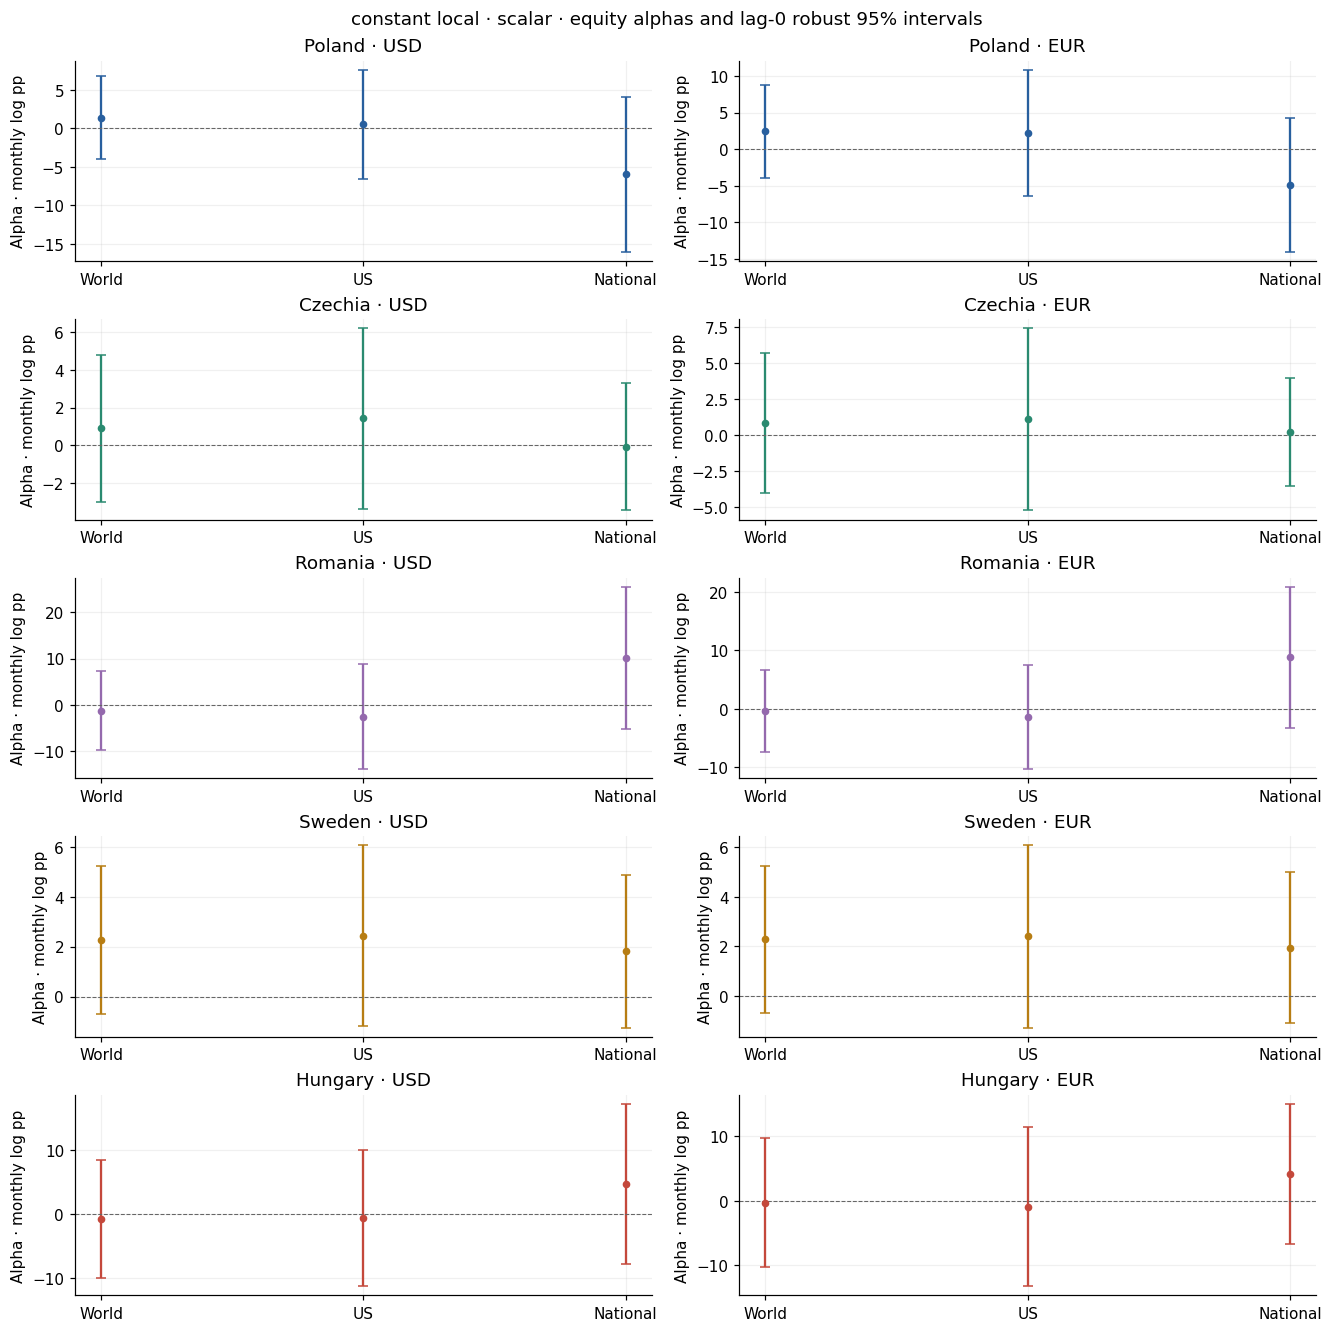

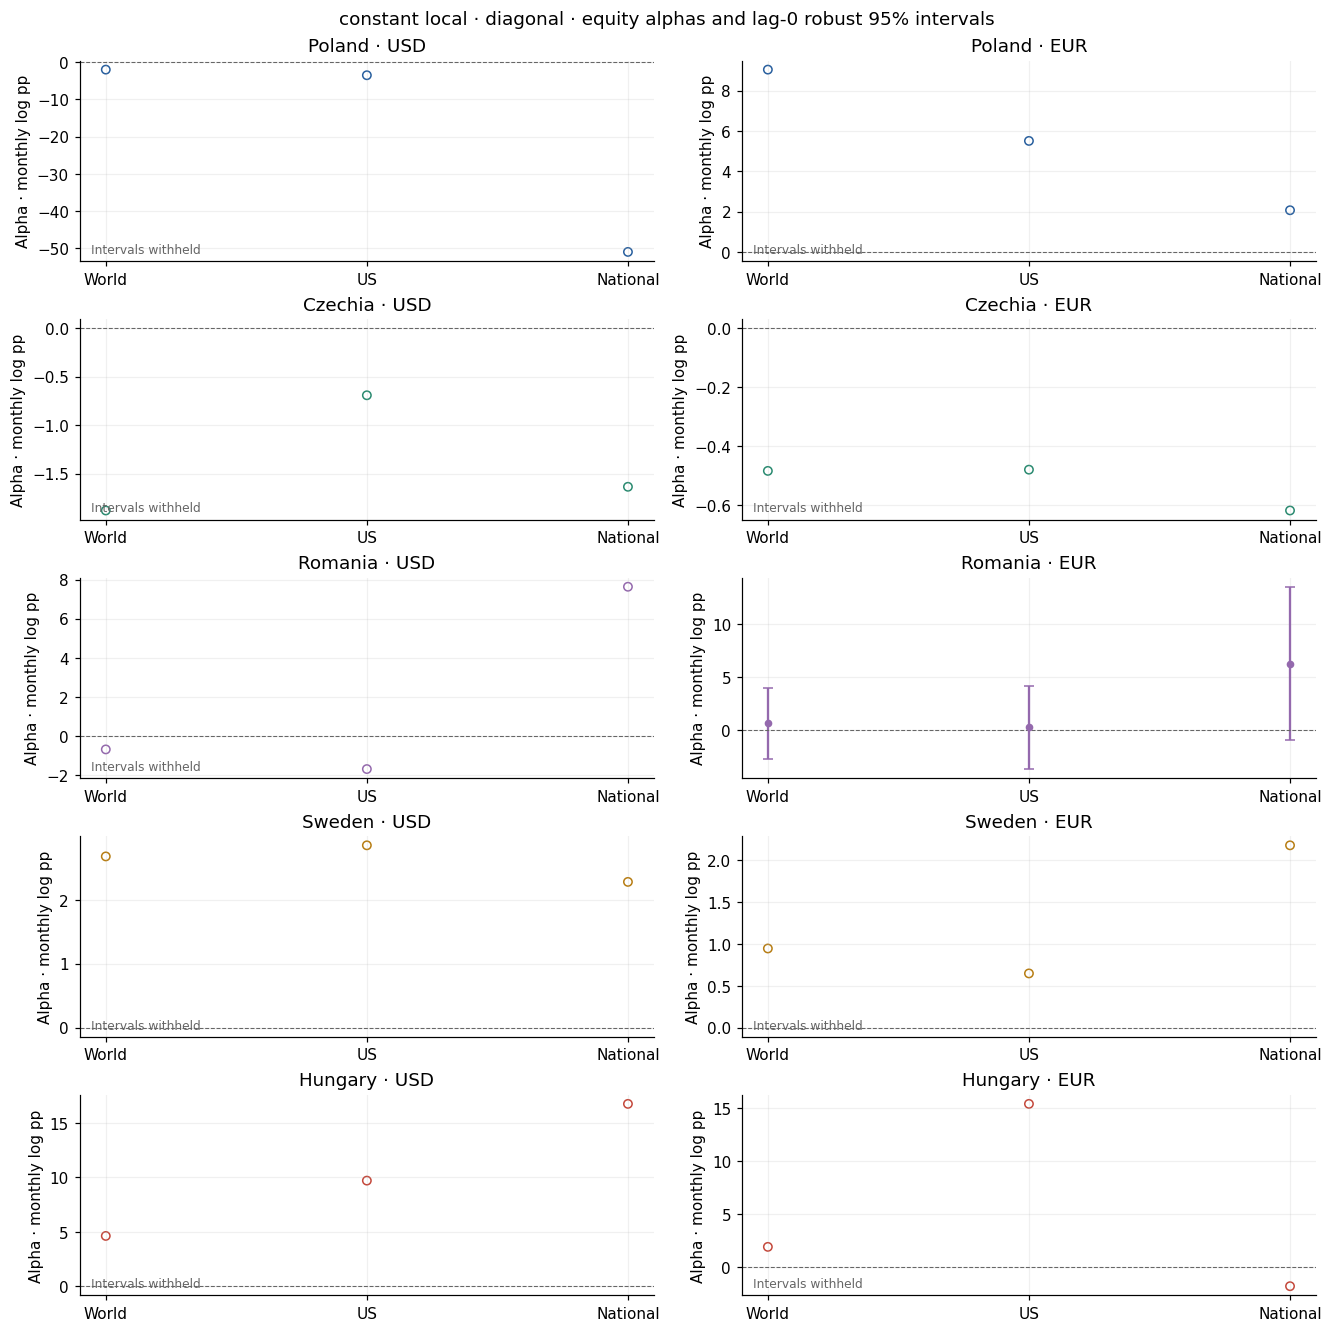

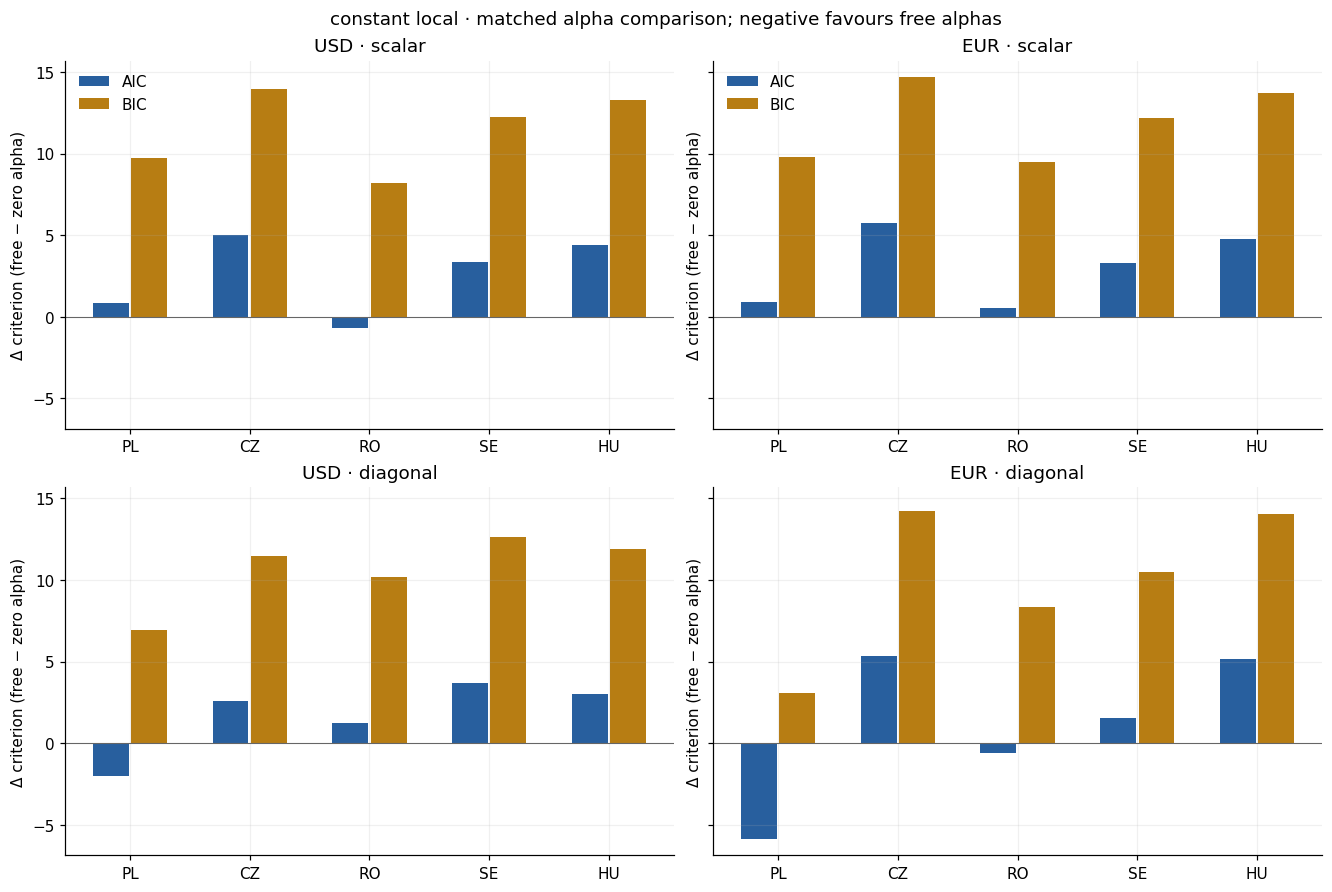

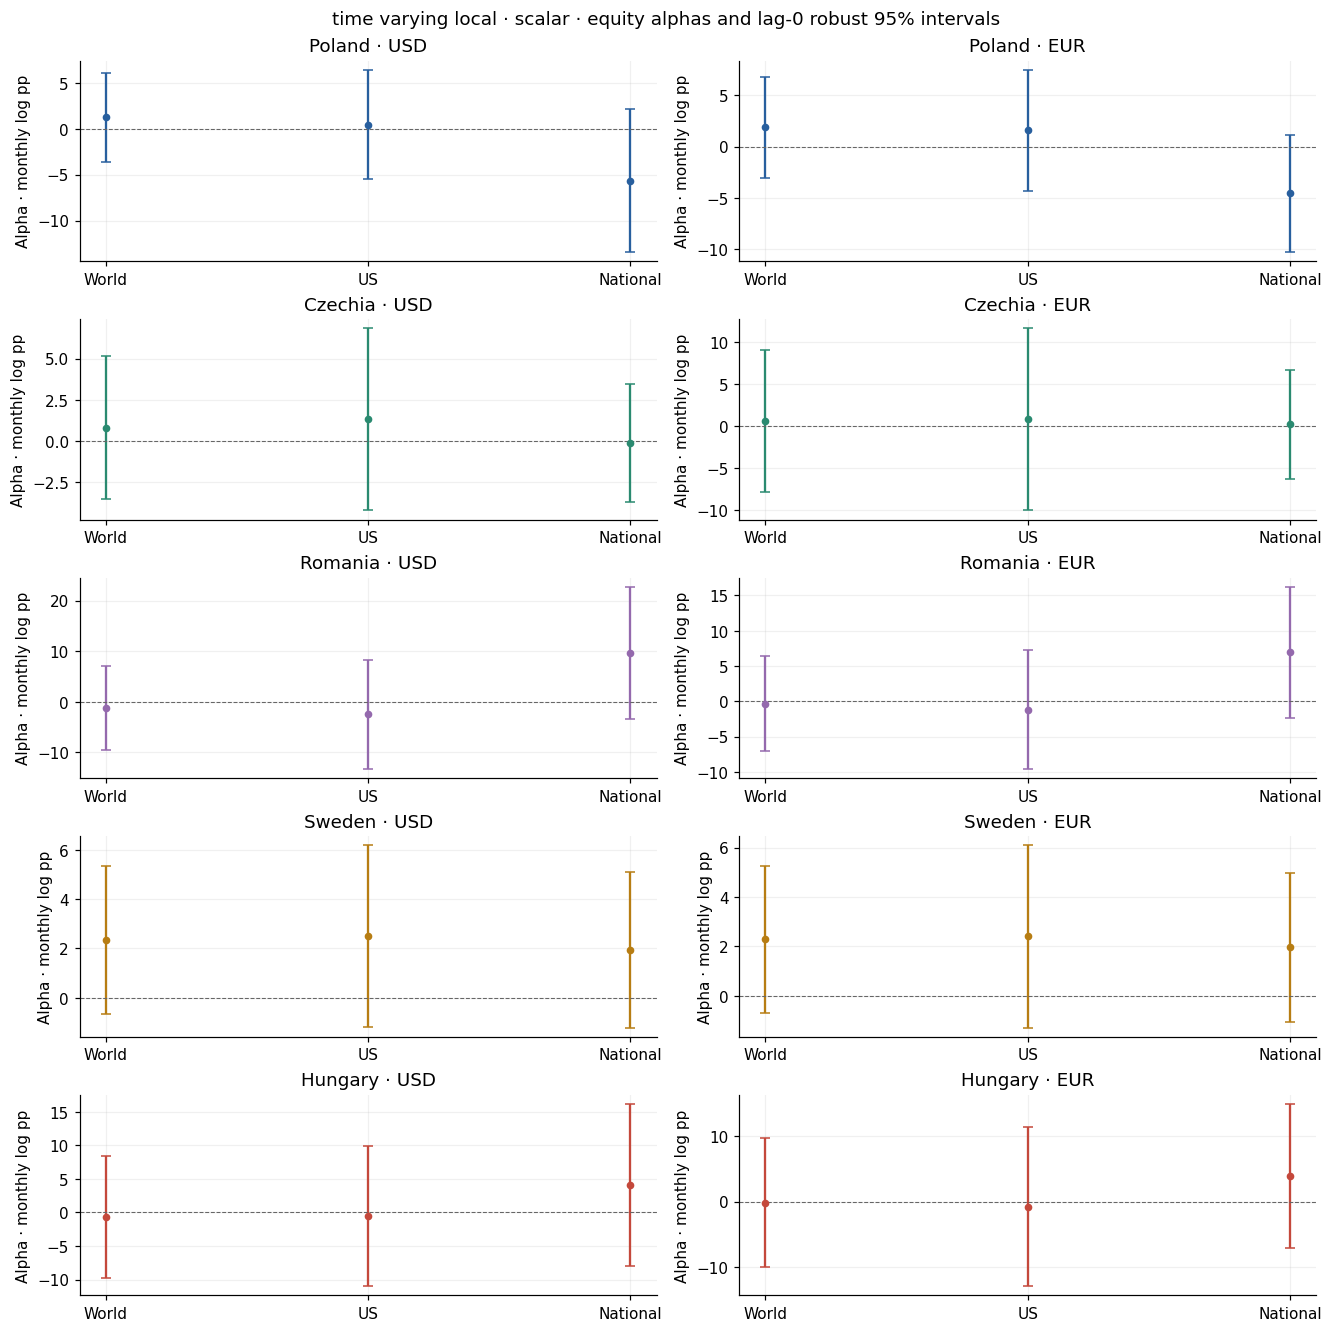

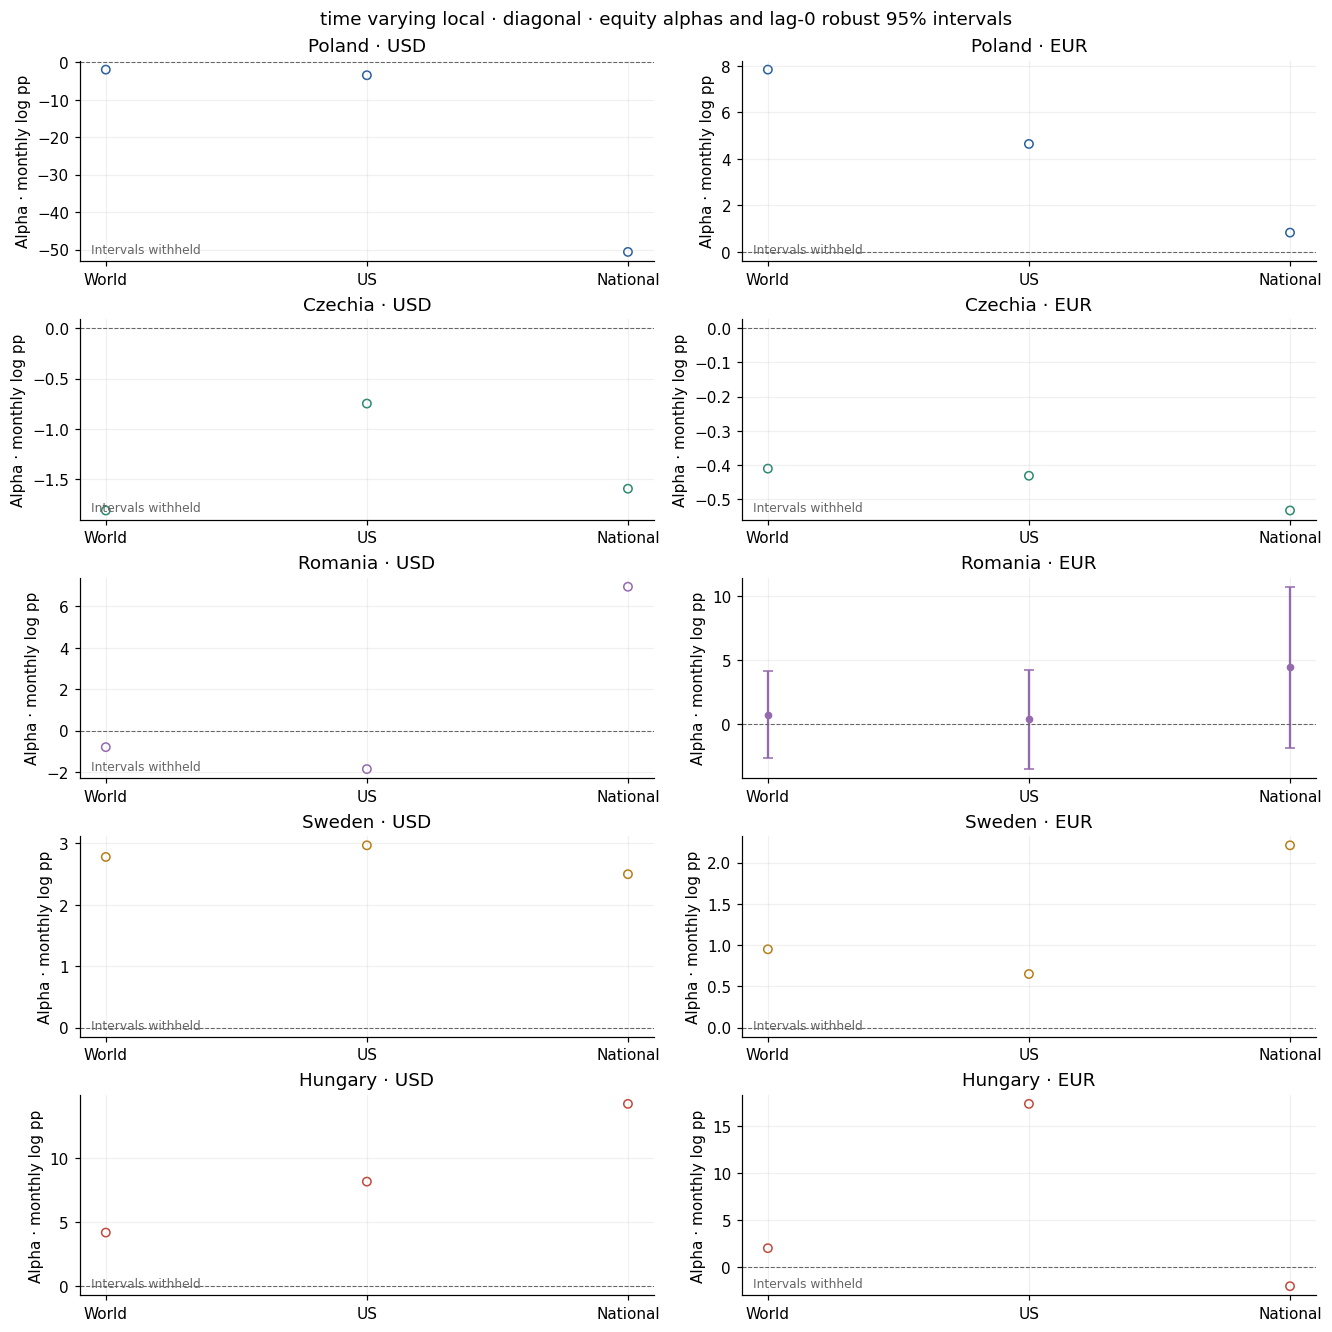

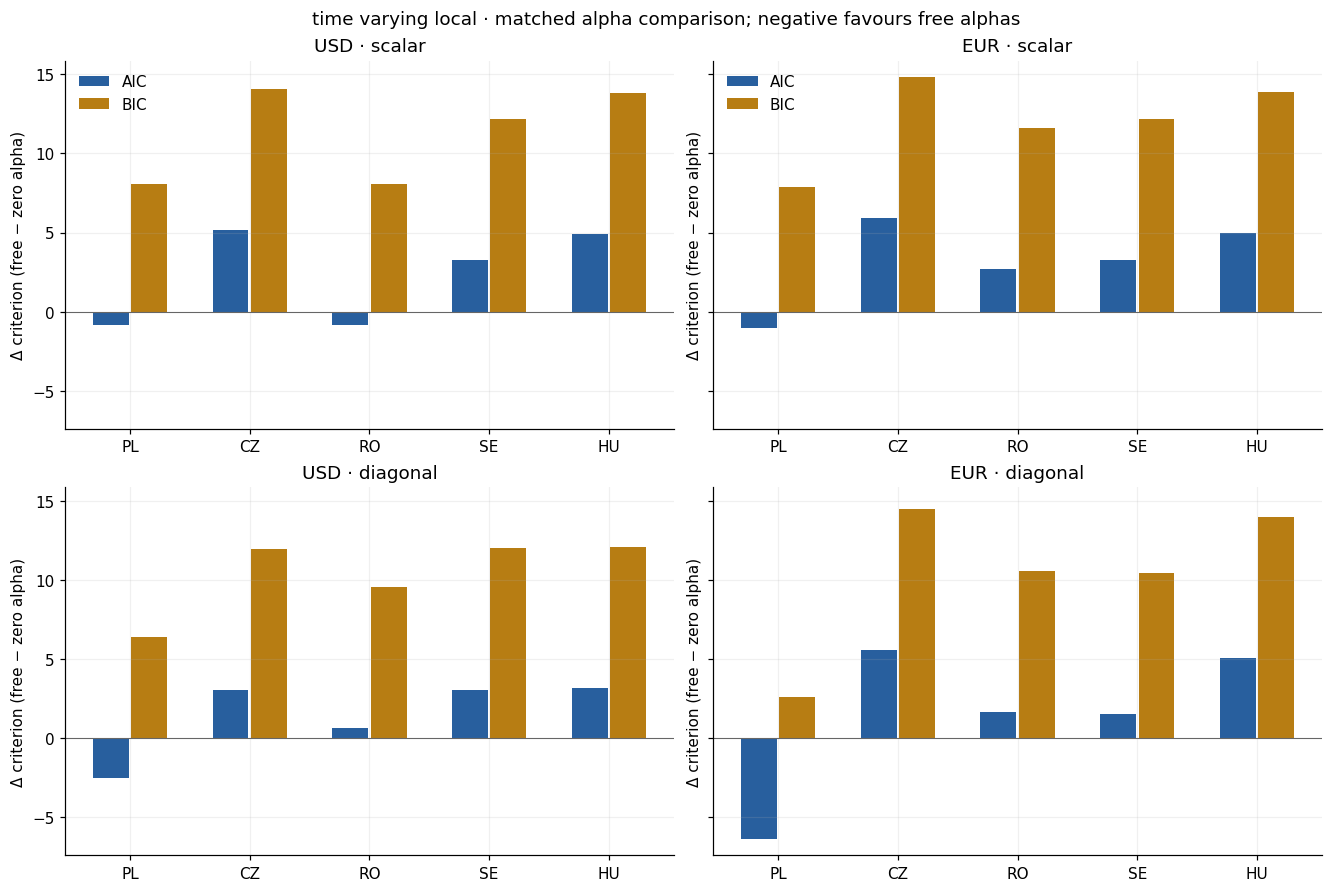

In [8]:
premium_rows, product_rows, comparison_rows, summary_rows = [], [], [], []
for (country, currency, covariance, local_form, model), fit in all_fits.items():
    f = fit["filter"]
    prices = {"world": f["world_prices"], "national_FX": f["fx_prices"][:, 0], "other_FX": f["fx_prices"][:, 1], "local": f["local_prices"]}
    covs = {"world": f["H"][:, 2, 0], "national_FX": f["H"][:, 2, 3], "other_FX": f["H"][:, 2, 4], "local": f["H"][:, 2, 2]}
    components = {a: prices[a]*covs[a] for a in prices}; pricing_total = sum(components.values())
    np.testing.assert_allclose(pricing_total, f["pricing_mu"][:, 2], atol=1e-11, rtol=0)
    np.testing.assert_allclose(pricing_total+f["equity_alphas"][2], f["mu"][:, 2], atol=1e-11, rtol=0)
    for risk, j in [("world", 0), ("national_FX", 3), ("other_FX", 4), ("local", 2)]:
        np.testing.assert_allclose(prices[risk].mean(), engine.PRICE_SCALE*fit["theta"][j], atol=1e-12, rtol=0)
    tags = {"country": country, "perspective": currency, "covariance": covariance, "local_form": local_form, "model": model}
    for risk in prices:
        product_rows.append({**tags, "component": risk, "mean_risk_price": prices[risk].mean(), "mean_covariance_pp2": covs[risk].mean(),
            "mean_contribution_pp": components[risk].mean(), "product_of_means_pp": prices[risk].mean()*covs[risk].mean(),
            "price_covariance_interaction_pp": components[risk].mean()-prices[risk].mean()*covs[risk].mean()})
    premium_rows.extend({**tags, "month": str(month), **{a+"_price": v[t] for a, v in prices.items()},
        **{a+"_covariance_pp2": v[t] for a, v in covs.items()}, **{a+"_premium_pp": v[t] for a, v in components.items()},
        "pricing_total_pp": pricing_total[t], "equity_alpha_pp": f["equity_alphas"][2], "fitted_mean_pp": f["mu"][t, 2],
        "observed_excess_pp": fit["y"][t, 2], "innovation_pp": f["errors"][t, 2]} for t, month in enumerate(months))
    if model != "free_alpha": continue
    select = "country == @country and perspective == @currency and covariance == @covariance and local_form == @local_form"
    same = fit_table.query(select).set_index("model")
    choose = lambda lag: tests.query(select+" and model == 'free_alpha' and restriction == 'Equity alphas jointly zero' and HAC_lag == @lag").p_value.iloc[0]
    da = same.loc[model, "AIC"]-same.loc["zero_alpha", "AIC"]; db = same.loc[model, "BIC"]-same.loc["zero_alpha", "BIC"]
    comparison_rows.append({**tags, "delta_AIC": da, "delta_BIC": db, "loglik_gain": same.loc[model, "loglik"]-same.loc["zero_alpha", "loglik"], "added_parameters": 3})
    r = residuals.query(select+" and model == 'free_alpha'"); c = cross.query(select+" and model == 'free_alpha'")
    a = alphas.query(select+" and model == 'free_alpha' and HAC_lag == 0").set_index("asset")
    summary_rows.append({"country": country, "name": NAMES[country], "perspective": currency, "covariance": covariance, "local_form": local_form,
        "months": len(months), **{f"joint_zero_alpha_p_HAC{h}": choose(h) for h in HAC_LAGS}, "delta_AIC": da, "delta_BIC": db,
        "alpha_world_pp": f["equity_alphas"][0], "alpha_US_pp": f["equity_alphas"][1], "alpha_national_pp": f["equity_alphas"][2],
        "national_alpha_SE_QML_pp": a.loc["National", "robust_se_pp"], "national_alpha_p_QML": a.loc["National", "p_value"],
        "national_alpha_p_holm3_QML": a.loc["National", "p_value_holm3"], "mean_pricing_total_pp": pricing_total.mean(),
        "mean_fitted_pp": f["mu"][:, 2].mean(), "mean_innovation_pp": f["errors"][:, 2].mean(),
        "mean_pricing_discrepancy_pp": (fit["y"][:, 2]-pricing_total).mean(),
        "numerical_inference_ready": fit["inference"]["estimates"][0]["ready"], "inference_reason": fit["inference"]["estimates"][0]["reason"],
        "mean_flags_holm_5pct": int(r.LB_z_p_holm.lt(.05).sum()),
        "variance_flags_holm_5pct": int((r.LB_z_squared_p_holm.lt(.05) | r.ARCH_LM_p_holm.lt(.05)).sum()),
        "cross_flags_holm_5pct": int(c.LB_product_p_holm.lt(.05).sum())})
premiums, product_summary, comparison, summary = map(pd.DataFrame, [premium_rows, product_rows, comparison_rows, summary_rows])
for local_form in LOCAL_FORMS:
    for covariance in COVARIANCES:
        fig, axes = plt.subplots(5, 2, figsize=(12, 12), layout="constrained")
        for row, country in enumerate(NAMES):
            for col, currency in enumerate(CURRENCIES):
                ax = axes[row, col]
                a = alphas.query("country == @country and perspective == @currency and covariance == @covariance and local_form == @local_form and model == 'free_alpha' and HAC_lag == 0").set_index("asset").loc[ASSETS[:3]]
                x = np.arange(3); ready = a.inference_ready.to_numpy()
                if ready.any(): ax.errorbar(x[ready], a.alpha_pp.to_numpy()[ready], yerr=1.96*a.robust_se_pp.to_numpy()[ready], fmt="o", color=COLORS[country], capsize=3, ms=4)
                if (~ready).any():
                    ax.scatter(x[~ready], a.alpha_pp.to_numpy()[~ready], facecolors="none", edgecolors=COLORS[country], s=30)
                    ax.text(.02, .04, "Intervals withheld", transform=ax.transAxes, color="#666666", fontsize=8)
                ax.axhline(0, color="#666666", lw=.7, ls="--")
                ax.set(xticks=x, xticklabels=ASSETS[:3], title=f"{NAMES[country]} · {currency}", ylabel="Alpha · monthly log pp")
        fig.suptitle(f"{local_form.replace('_', ' ')} · {covariance} · equity alphas and lag-0 robust 95% intervals")
        save_plot(f"01_alphas_{local_form}_{covariance}.png")
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True, layout="constrained")
    for row, covariance in enumerate(COVARIANCES):
        for col, currency in enumerate(CURRENCIES):
            ax = axes[row, col]
            p = comparison.query("perspective == @currency and covariance == @covariance and local_form == @local_form").set_index("country").loc[list(NAMES)]
            x = np.arange(5)
            ax.bar(x-.16, p.delta_AIC, width=.3, color="#285f9e", label="AIC"); ax.bar(x+.16, p.delta_BIC, width=.3, color="#b77d13", label="BIC")
            ax.axhline(0, color="#666666", lw=.7)
            ax.set(xticks=x, xticklabels=list(NAMES), title=f"{currency} · {covariance}", ylabel="Δ criterion (free − zero alpha)")
            if row == 0: ax.legend(frameon=False)
    fig.suptitle(f"{local_form.replace('_', ' ')} · matched alpha comparison; negative favours free alphas")
    save_plot(f"02_model_comparison_{local_form}.png")

## 8. Final comparison and reproducibility

The main table uses the common constant-local specification; the second table retains the same
varying-local sensitivity for all countries. Distinguish numerical availability, the three-df joint
test, individual alpha tests, information criteria and residual adequacy. Missing tests are unavailable,
not non-rejections. Inspect every bandwidth; shared data and the exploratory sequence limit strong
claims. Neither significant alphas nor their absence alone establishes economic inefficiency.

The next step is a consistent, zero-alpha final pricing-model comparison across countries, followed
by regional robustness and synthesis. Free-alpha results remain a specification check; pricing errors
are not relabelled as world, FX or local risk compensation.

In [9]:
for local_form in LOCAL_FORMS:
    display(Markdown(f"**{'Main comparison' if local_form == 'constant_local' else 'Sensitivity'}: {local_form.replace('_', ' ')}**"))
    g = summary.query("local_form == @local_form").set_index(["name", "perspective", "covariance"])
    display(g[["joint_zero_alpha_p_HAC0", "joint_zero_alpha_p_HAC12", "alpha_national_pp", "national_alpha_SE_QML_pp", "delta_AIC", "delta_BIC", "numerical_inference_ready"]].round(5))
    display(g[["inference_reason", "mean_flags_holm_5pct", "variance_flags_holm_5pct", "cross_flags_holm_5pct"]])
tables = {"input_audit.csv": input_audit, "source_design_audit.csv": source_design_audit, "design_audit.csv": design_audit,
    "instrument_transform.csv": transform_table, "conditioning_design.csv": conditioning, "inflation_quality_flags.csv": quality_flags,
    "implementation_checks.csv": checks, "mean_loading_audit.csv": mean_loading_audit, "starting_points.csv": starts_table,
    "fit_summary.csv": fit_table, "alpha_estimates.csv": alphas, "price_coefficients.csv": coefficients, "restriction_tests.csv": tests,
    "inference_audit.csv": inference_audit, "parameter_bounds.csv": boundary_audit, "risk_price_paths.csv": price_paths,
    "residual_diagnostics.csv": residuals, "cross_covariance_diagnostics.csv": cross, "mean_discrepancies.csv": mean_discrepancies,
    "premium_components.csv": premiums, "price_covariance_products.csv": product_summary, "model_comparison.csv": comparison,
    "common_comparison.csv": summary}
for name, frame in tables.items(): frame.to_csv(OUT/name, index=False, float_format="%.17g", lineterminator="\n")
parameter_files = []
for (country, currency, covariance, local_form, model), fit in all_fits.items():
    name = f"parameters_{country}_{currency}_{covariance}_{local_form}_{model}.npz"; f = fit["filter"]
    np.savez(OUT/name, theta=fit["theta"], H=f["H"], mu=f["mu"], pricing_mu=f["pricing_mu"], errors=f["errors"], scores=f["scores"],
        equity_alphas=f["equity_alphas"], target=f["target"], intercept=f["intercept"], Hessian=fit["inference"]["Hessian"],
        **{f"covariance_HAC{h}": e["covariance"] for h, e in fit["inference"]["estimates"].items()})
    parameter_files.append(name)
_, after_hashes = verify_inputs()
assert input_hashes == after_hashes and engine_hashes == {name: sha((ROOT/name).read_bytes()) for name in engine_hashes}
outputs = [*tables, *figure_files, *parameter_files]+[f"fit_{c}_{p}_{v}_{l}_free_alpha.json" for c, p, v, l in fits]
metadata = {"notebook": "27_regional_pricing_errors.ipynb", "model_version": MODEL_VERSION, "engines": engine_hashes,
    "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA, "first": str(months[0]), "last": str(months[-1]), "observations_per_fit": len(months),
    "estimated_fits": len(fits), "zero_alpha_reference_fits": len(zero_fits), "input_locks": LOCK_HASHES, "input_file_hashes": input_hashes,
    "spec": spec, "designs": design_audit.to_dict("records"), "settings": {"START_DYNAMICS": START_DYNAMICS, "MAX_ITER": MAX_ITER, "MAX_ITER_OVERRIDES": {"/".join(k): v for k, v in MAX_ITER_OVERRIDES.items()}, "TEST_LAGS": TEST_LAGS, "HAC_LAGS": HAC_LAGS},
    "python": sys.executable, "python_version": platform.python_version(), "packages": versions,
    "outputs": {name: sha((OUT/name).read_bytes()) for name in outputs},
    "notes": ["Same frozen 144 months and base; constant-local main comparison and common time-varying-local sensitivity",
        "Three free equity alphas scaled by fixed equity SD; no alpha bounds; no added FX intercepts",
        "Corrected FX means; unchanged world/FX/local conditioners; all free parameters jointly re-estimated",
        "Joint three-df zero-alpha Wald from full robust covariance; individual alpha Holm family of three",
        "Fixed QML/HAC 0/3/6/12; alpha and risk-price SE stability; invalid inference suppressed",
        "Joint tests exploratory/unadjusted; investor and country views dependent; no Gaussian LR p-values",
        "Pricing-only discrepancies, alphas and innovations separated; alpha excluded from risk-premium components"]}
(OUT/"estimation_manifest.json").write_text(json.dumps(metadata, indent=2, sort_keys=True)+"\n")
for local_form in LOCAL_FORMS:
    g = summary.query("local_form == @local_form")
    counts = lambda h: f"{int(g[f'joint_zero_alpha_p_HAC{h}'].lt(.05).sum())}/{int(g[f'joint_zero_alpha_p_HAC{h}'].notna().sum())}"
    display(Markdown(f"**{local_form.replace('_', ' ')}:** joint zero-alpha rejections at an unadjusted 5% level: "
        f"**{counts(0)}** available lag-0 tests; **{counts(12)}** available lag-12 tests. "
        f"AIC favours free alphas in **{int(g.delta_AIC.lt(0).sum())}/20** comparisons; BIC in **{int(g.delta_BIC.lt(0).sum())}/20**. "
        f"**{int((~g.numerical_inference_ready).sum())}/20** systems have suppressed primary numerical inference."))
display(Markdown(f"**Completed:** {len(fits)} free-alpha fits and {len(zero_fits)} verified zero-alpha references; "
    f"all on **{months[0]}–{months[-1]} ({len(months)} months)** in base. "
    f"Saved {len(tables)} tables and {len(figure_files)} charts in `{OUT.relative_to(ROOT)}`. Frozen inputs and prior outputs are unchanged."))

**Main comparison: constant local**

joint_zero_alpha_p_HAC0  \
name    perspective covariance                            
Hungary USD         scalar                      0.81849   
                    diagonal                        NaN   
        EUR         scalar                      0.84832   
                    diagonal                        NaN   
Poland  USD         scalar                      0.56610   
                    diagonal                        NaN   
        EUR         scalar                      0.53016   
                    diagonal                        NaN   
Czechia USD         scalar                      0.85658   
                    diagonal                        NaN   
        EUR         scalar                      0.97583   
                    diagonal                        NaN   
Romania USD         scalar                      0.57155   
                    diagonal                        NaN   
        EUR         scalar                      0.51477   
                    diagonal                    0.17775   
Sweden  USD         scalar                      0.49762   
                    diagonal                        NaN   
        EUR         scalar                      0.48481   
                    diagonal                        NaN   

                                joint_zero_alpha_p_HAC12  alpha_national_pp  \
name    perspective covariance                                                
Hungary USD         scalar                       0.78527            4.65886   
                    diagonal                         NaN           16.77305   
        EUR         scalar                       0.72334            4.17019   
                    diagonal                         NaN           -1.79747   
Poland  USD         scalar                       0.58105           -5.96086   
                    diagonal                         NaN          -51.03367   
        EUR         scalar                       0.48560           -4.87276   
                    diagonal                         NaN            2.06788   
Czechia USD         scalar                       0.57078           -0.07989   
                    diagonal                         NaN           -1.63681   
        EUR         scalar                       0.89057            0.21715   
                    diagonal                         NaN           -0.61831   
Romania USD         scalar                       0.56508           10.19603   
                    diagonal                         NaN            7.63206   
        EUR         scalar                       0.55252            8.78888   
                    diagonal                     0.31267            6.27886   
Sweden  USD         scalar                       0.27131            1.81042   
                    diagonal                         NaN            2.27818   
        EUR         scalar                       0.28131            1.95433   
                    diagonal                         NaN            2.17987   

                                national_alpha_SE_QML_pp  delta_AIC  \
name    perspective covariance                                        
Hungary USD         scalar                       6.37377    4.38599   
                    diagonal                         NaN    2.99142   
        EUR         scalar                       5.52322    4.78907   
                    diagonal                         NaN    5.14842   
Poland  USD         scalar                       5.13450    0.83326   
                    diagonal                         NaN   -1.99394   
        EUR         scalar                       4.68011    0.88604   
                    diagonal                         NaN   -5.83796   
Czechia USD         scalar                       1.73234    5.03448   
                    diagonal                         NaN    2.57030   
        EUR         scalar                       1.90516    5.76411   
                    diagonal                         NaN    5.33719   


inference_reason  \
name    perspective covariance                                                      
Hungary USD         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
        EUR         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
Poland  USD         scalar                                      numerically ready   
                    diagonal    parameter bound; nonpositive curvature; ill-co...   
        EUR         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
Czechia USD         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
        EUR         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
Romania USD         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
        EUR         scalar                                      numerically ready   
                    diagonal                                    numerically ready   
Sweden  USD         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
        EUR         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   

                                mean_flags_holm_5pct  \
name    perspective covariance                         
Hungary USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Poland  USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Czechia USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Romania USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Sweden  USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   

                                variance_flags_holm_5pct  \
name    perspective covariance                             
Hungary USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Poland  USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Czechia USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Romania USD         scalar                             0   
                    diagonal                           0   
 

**Sensitivity: time varying local**

joint_zero_alpha_p_HAC0  \
name    perspective covariance                            
Hungary USD         scalar                      0.83938   
                    diagonal                        NaN   
        EUR         scalar                      0.87368   
                    diagonal                        NaN   
Poland  USD         scalar                      0.43293   
                    diagonal                        NaN   
        EUR         scalar                      0.38152   
                    diagonal                        NaN   
Czechia USD         scalar                      0.87037   
                    diagonal                        NaN   
        EUR         scalar                      0.99287   
                    diagonal                        NaN   
Romania USD         scalar                      0.48478   
                    diagonal                        NaN   
        EUR         scalar                      0.51730   
                    diagonal                    0.23850   
Sweden  USD         scalar                      0.49181   
                    diagonal                        NaN   
        EUR         scalar                      0.48680   
                    diagonal                        NaN   

                                joint_zero_alpha_p_HAC12  alpha_national_pp  \
name    perspective covariance                                                
Hungary USD         scalar                       0.78085            4.08738   
                    diagonal                         NaN           14.21040   
        EUR         scalar                       0.72475            3.91269   
                    diagonal                         NaN           -2.03664   
Poland  USD         scalar                       0.47272           -5.64916   
                    diagonal                         NaN          -50.63651   
        EUR         scalar                       0.37691           -4.56373   
                    diagonal                         NaN            0.83012   
Czechia USD         scalar                       0.63471           -0.13012   
                    diagonal                         NaN           -1.59515   
        EUR         scalar                       0.97003            0.17395   
                    diagonal                         NaN           -0.53352   
Romania USD         scalar                       0.45581            9.66186   
                    diagonal                         NaN            6.94939   
        EUR         scalar                       0.47916            6.91988   
                    diagonal                     0.31576            4.42894   
Sweden  USD         scalar                       0.27937            1.95059   
                    diagonal                         NaN            2.49700   
        EUR         scalar                       0.28029            1.96207   
                    diagonal                         NaN            2.20854   

                                national_alpha_SE_QML_pp  delta_AIC  \
name    perspective covariance                                        
Hungary USD         scalar                       6.17975    4.88528   
                    diagonal                         NaN    3.19639   
        EUR         scalar                       5.60034    5.00214   
                    diagonal                         NaN    5.07613   
Poland  USD         scalar                       3.96134   -0.81960   
                    diagonal                         NaN   -2.50989   
        EUR         scalar                       2.90036   -1.01845   
                    diagonal                         NaN   -6.33248   
Czechia USD         scalar                       1.81693    5.13986   
                    diagonal                         NaN    3.05970   
        EUR         scalar                       3.32007    5.90247   
                    diagonal                         NaN    5.58074   


inference_reason  \
name    perspective covariance                                                      
Hungary USD         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
        EUR         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
Poland  USD         scalar                                      numerically ready   
                    diagonal    parameter bound; nonpositive curvature; ill-co...   
        EUR         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
Czechia USD         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
        EUR         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
Romania USD         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
        EUR         scalar                                      numerically ready   
                    diagonal                                    numerically ready   
Sweden  USD         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   
        EUR         scalar                                      numerically ready   
                    diagonal           parameter bound; ill-conditioned curvature   

                                mean_flags_holm_5pct  \
name    perspective covariance                         
Hungary USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Poland  USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Czechia USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Romania USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Sweden  USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   

                                variance_flags_holm_5pct  \
name    perspective covariance                             
Hungary USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Poland  USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Czechia USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Romania USD         scalar                             0   
                    diagonal                           0   
 

**constant local:** joint zero-alpha rejections at an unadjusted 5% level: **0/11** available lag-0 tests; **0/11** available lag-12 tests. AIC favours free alphas in **4/20** comparisons; BIC in **0/20**. **9/20** systems have suppressed primary numerical inference.

**time varying local:** joint zero-alpha rejections at an unadjusted 5% level: **0/11** available lag-0 tests; **0/11** available lag-12 tests. AIC favours free alphas in **5/20** comparisons; BIC in **0/20**. **9/20** systems have suppressed primary numerical inference.

**Completed:** 40 free-alpha fits and 40 verified zero-alpha references; all on **2014-10–2026-09 (144 months)** in base. Saved 23 tables and 6 charts in `output/27_regional_pricing_errors/2014-10_2026-09/alpha_d0d69f20`. Frozen inputs and prior outputs are unchanged.